# Pull × Air Quadrant Model — Frontier League v2 (LA-Corrected PAD)

Rebuild of the FL Pull × Air analysis with the **LA-corrected Preferred Attack
Direction** as the primary direction metric, following the MLB validation:

- Raw envelope PAD topped out at split-half r_full ≈ 0.60–0.76 and required
  150–250 BBE to stabilize.
- **PAD_lac** (LA-corrected): per hitter, regress `spray_pull ~ angle`, then
  evaluate that line at the hitter's own PAA. In MLB this improved
  agreement with measured attack direction (held-out r 0.489 → 0.637) and
  split-half reliability at every BBE threshold (e.g. 0.60 → 0.84 at BBE≥100).
- Mechanism: the spray↔EV relationship is nearly flat (weak PAD signal), but
  the spray↔launch-angle relationship is strong and consistent — so the
  correction routes direction estimation through PAA's much stronger reliability.

**Pipeline**
1. FL BBE pull (validated conventions)
2. Visual validation: per-batter spray vs LA slope (the relationship the fix relies on)
3. PAA, raw PAD, and **PAD_lac** per batter-year
4. Split-half reliability: raw PAD vs PAD_lac (fast joblib pipeline)
5. Quadrant assignment + correlations (PAD_lac as the direction feature)
6. Multinomial classifiers + direct Pull Air% regression
7. wOBAcon by quadrant + YoY stickiness (incl. PAD_lac)
8. Plate-discipline profile by quadrant (K%, BB%, contact, two-strike contact)
9. Final deliverable

## 1. Imports & Config

In [25]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from scipy.stats import spearmanr, pearsonr, f_oneway, kruskal
from dotenv import load_dotenv
from sqlalchemy import create_engine, text, bindparam
from joblib import Parallel, delayed

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             cohen_kappa_score, accuracy_score, r2_score)

pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", "{:.3f}".format)

# ── Validated FL conventions ──────────────────────────────────────────────────
PULL_CUTOFF_DEG = 15          # reproduces ≈.36 league Pull%
AIR_LA_MIN      = 10          # LD/FB/PU
DIR_RANGE       = (-45, 45)   # physical spray window

# ── Envelope (Marshall) parameters ────────────────────────────────────────────
ANGLE_MIN, ANGLE_MAX = -30, 60
SPRAY_MIN, SPRAY_MAX = -45, 45
BIN_WIDTH        = 3
TOP_FRAC_PER_BIN = 0.20
TOP_N_METHOD2    = 15

# ── LA-correction parameters ──────────────────────────────────────────────────
MIN_BBE_LAC = 30              # minimum BBE for a per-hitter spray~LA regression

# ── Qualification ─────────────────────────────────────────────────────────────
MIN_BBE = 100                 # per batter-year

QUAD_ORDER  = ["Neither", "Pull only", "Air only", "Both"]
QUAD_COLORS = {"Neither": "#9E9E9E", "Pull only": "#E65100",
               "Air only": "#1565C0", "Both": "#1B5E20"}

print("Config OK")

Config OK


## 2. Metric Functions — PAA, Raw PAD, LA-Corrected PAD

Numpy-array versions throughout (same machinery as the fast reliability pipeline),
so the split-half analysis in §5 reuses these directly with no pandas overhead.

In [26]:
def _envelope_peak_arrays(x, ev, x_min, x_max):
    """Marshall envelope on raw numpy arrays: top-20%-per-bin parabola peak
    averaged with the top-15-by-EV mean."""
    mask = (x >= x_min) & (x <= x_max) & ~np.isnan(x) & ~np.isnan(ev)
    x, ev = x[mask], ev[mask]
    if len(x) < 10:
        return np.nan

    k2 = min(TOP_N_METHOD2, max(3, int(np.ceil(0.2 * len(x)))))
    top2_idx = np.argpartition(ev, -k2)[-k2:] if len(ev) > k2 else np.arange(len(ev))
    method2 = x[top2_idx].mean()

    bins = np.arange(x_min, x_max + BIN_WIDTH, BIN_WIDTH)
    bin_idx = np.digitize(x, bins)

    env_x_parts, env_ev_parts = [], []
    for b_i in np.unique(bin_idx):
        m = bin_idx == b_i
        sub_x, sub_ev = x[m], ev[m]
        if len(sub_x) == 0:
            continue
        k = max(1, int(np.ceil(TOP_FRAC_PER_BIN * len(sub_x))))
        idx = np.argpartition(sub_ev, -k)[-k:] if len(sub_ev) > k else np.arange(len(sub_ev))
        env_x_parts.append(sub_x[idx])
        env_ev_parts.append(sub_ev[idx])

    if not env_x_parts:
        return method2
    env_x  = np.concatenate(env_x_parts)
    env_ev = np.concatenate(env_ev_parts)
    if len(env_x) < 5:
        return method2

    a, b, c = np.polyfit(env_x, env_ev, deg=2)
    if a < 0:
        v = -b / (2 * a)
        if x_min <= v <= x_max:
            method1 = v
        else:
            xs = np.linspace(x_min, x_max, 361)
            method1 = xs[np.argmax(np.polyval([a, b, c], xs))]
    else:
        method1 = env_x[np.argmax(env_ev)]

    return np.nanmean([method1, method2])


def _la_corrected_pad_arrays(la, sp, paa_val, min_n=MIN_BBE_LAC):
    """
    LA-corrected PAD: regress spray_pull on launch angle for this hitter,
    then evaluate the fitted line at the hitter's own PAA.
    Routes direction estimation through the strong, consistent spray↔LA
    relationship instead of the nearly-flat spray↔EV one.
    """
    mask = ~np.isnan(la) & ~np.isnan(sp)
    la_c, sp_c = la[mask], sp[mask]
    if len(la_c) < min_n or np.isnan(paa_val):
        return np.nan
    slope, intercept, *_ = stats.linregress(la_c, sp_c)
    return intercept + slope * paa_val


def compute_metrics_for_group(la, ev, sp):
    """Returns (PAA, PAD_raw, PAD_lac) for one batter-year's arrays."""
    paa     = _envelope_peak_arrays(la, ev, ANGLE_MIN, ANGLE_MAX)
    pad_raw = _envelope_peak_arrays(sp, ev, SPRAY_MIN, SPRAY_MAX)
    pad_lac = _la_corrected_pad_arrays(la, sp, paa)
    return paa, pad_raw, pad_lac

print("Metric functions defined")

Metric functions defined


## 3. FL Pull — BBE with Outcomes

In [27]:
ENV_PATH = r"C:/Users/215nt/PycharmProjects/FLStuff/FLPitching/FLCommand/.env"

def get_engine():
    load_dotenv(ENV_PATH)
    host     = os.getenv("SUPABASE_HOST", "aws-1-us-east-1.pooler.supabase.com")
    port     = os.getenv("SUPABASE_PORT", "6543")
    dbname   = os.getenv("SUPABASE_DB",   "postgres")
    user     = os.getenv("SUPABASE_USER")
    password = os.getenv("SUPABASE_PASSWORD")
    return create_engine(
        f"postgresql+psycopg2://{user}:{password}@{host}:{port}/{dbname}?sslmode=require",
        pool_pre_ping=True,
        pool_recycle=300,
    )

SQL = """
SELECT
    batter,
    batter_team,
    batter_side,
    year,
    exit_speed,
    angle,
    direction,
    play_result
FROM pitches
WHERE pitch_call = 'in_play'
  AND exit_speed IS NOT NULL
  AND angle      IS NOT NULL
  AND direction  IS NOT NULL
  AND batter     IS NOT NULL
"""

engine = get_engine()
with engine.connect() as conn:
    fl_raw = pd.read_sql(text(SQL), conn)

print(f"FL BBE rows: {len(fl_raw):,}   batters: {fl_raw['batter'].nunique()}")
print(f"Years: {sorted(fl_raw['year'].dropna().unique())}")

FL BBE rows: 66,829   batters: 588
Years: [np.float64(2025.0), np.float64(2026.0)]


## 4. Conventions, Flags & wOBAcon Weights

In [28]:
FL_HAND_MAP = {"Left": "L", "Right": "R", "left": "L", "right": "R"}

n0 = len(fl_raw)
fl = fl_raw[fl_raw["batter_side"] != "undefined"].copy()
print(f"Dropped {n0 - len(fl):,} rows with undefined batter_side")

unmapped = fl.loc[~fl["batter_side"].isin(FL_HAND_MAP), "batter_side"].unique()
assert len(unmapped) == 0, f"Unmapped batter_side values: {list(unmapped)}"
fl["stand"] = fl["batter_side"].map(FL_HAND_MAP)

n0 = len(fl)
fl = fl[fl["direction"].between(*DIR_RANGE)].copy()
print(f"Direction filter: dropped {n0 - len(fl):,} rows")

fl = fl.dropna(subset=["year"]).copy()
fl["year"] = fl["year"].astype(int)

# Mirrored spray: pull-positive both hands (validated convention)
fl["spray_pull"] = np.where(fl["stand"] == "R", -fl["direction"], fl["direction"])
fl["is_pull"]    = fl["spray_pull"] > PULL_CUTOFF_DEG
fl["is_air"]     = fl["angle"] >= AIR_LA_MIN
fl["pull_air"]   = fl["is_pull"] & fl["is_air"]
fl["hard_hit"]   = fl["exit_speed"] >= 95

print(f"\nFL league Pull%    : {fl['is_pull'].mean():.3f}   (expect ≈ .36)")
print(f"FL league Air%     : {fl['is_air'].mean():.3f}")
print(f"FL league PullAir% : {fl['pull_air'].mean():.3f}")

WOBA_W = {"single": 0.935, "double": 1.289, "triple": 1.525,
          "homerun": 2.146, "home_run": 2.146}
fl["pr_norm"]  = fl["play_result"].astype(str).str.lower().str.replace(" ", "")
fl["woba_val"] = fl["pr_norm"].map(WOBA_W).fillna(0.0)

mapped_hits = fl.loc[fl["woba_val"] > 0, "pr_norm"].value_counts()
print("\nHit categories mapped for wOBAcon:")
print(mapped_hits)
assert len(mapped_hits) >= 3, "Hit categories not mapping — check play_result values"


Dropped 25 rows with undefined batter_side
Direction filter: dropped 4,404 rows

FL league Pull%    : 0.361   (expect ≈ .36)
FL league Air%     : 0.565
FL league PullAir% : 0.157

Hit categories mapped for wOBAcon:
pr_norm
single      15481
double       4218
home_run     2368
triple        369
Name: count, dtype: int64


## 5. Visual Validation — Spray vs LA Slope (Per Batter)

The LA-correction relies on a strong, consistent per-hitter `spray_pull ~ angle`
relationship. This was clean and negative-sloped for every sampled MLB hitter;
verify the same pattern holds in FL before trusting the corrected metric.

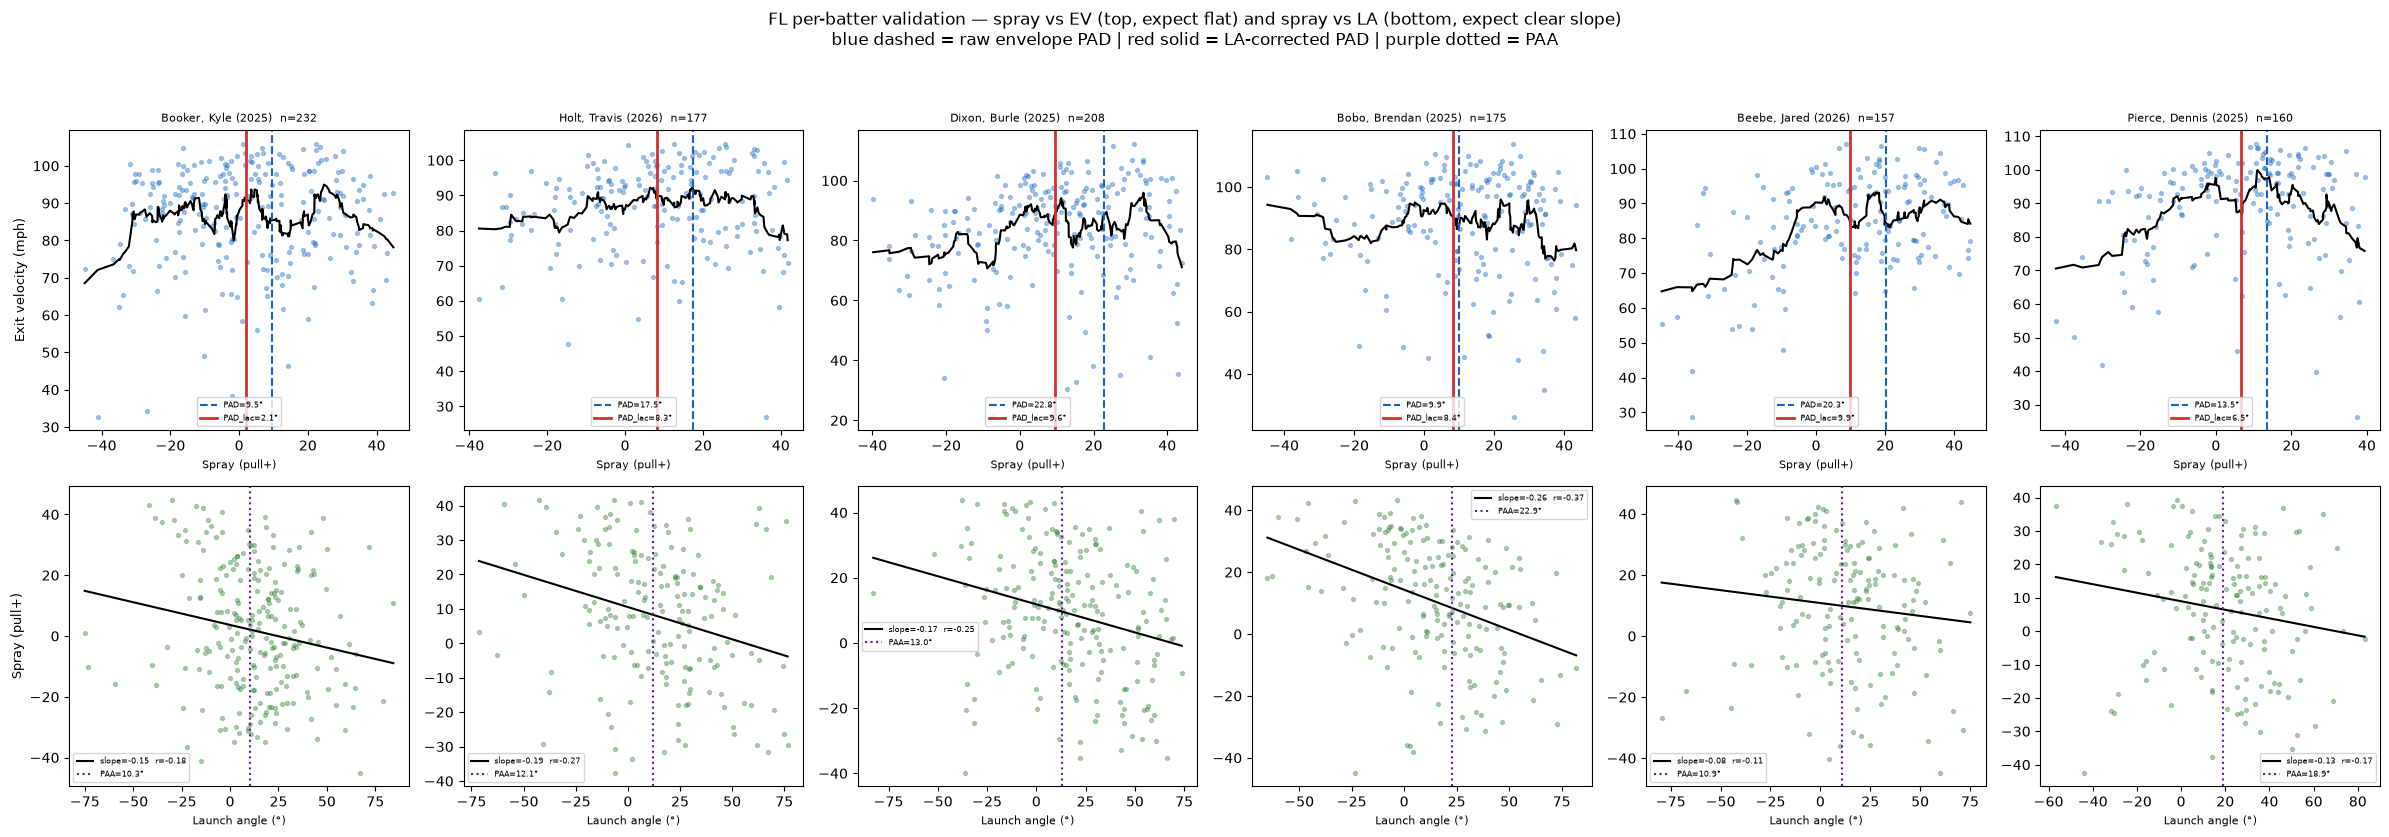

Batter-years with spray~LA fit (n≥30): 494
Median slope: -0.211   Median |r|: 0.278
Share with negative slope (MLB pattern): 96.2%


In [29]:
viz_candidates = (fl.groupby(["batter", "year"]).size()
                  .pipe(lambda s: s[s >= 150]).reset_index()[["batter", "year"]])
viz_sample = viz_candidates.sample(min(6, len(viz_candidates)),
                                   random_state=4).itertuples(index=False)

fig, axes = plt.subplots(2, 6, figsize=(24, 8))
for col, (b, y) in enumerate(viz_sample):
    g = fl[(fl["batter"] == b) & (fl["year"] == y)]
    la, ev, sp = (g["angle"].to_numpy(), g["exit_speed"].to_numpy(),
                  g["spray_pull"].to_numpy())
    paa, pad_raw, pad_lac = compute_metrics_for_group(la, ev, sp)

    g_sorted = g.sort_values("spray_pull")

    # Row 1: spray vs EV — expect near-flat (the weak signal)
    ax1 = axes[0, col]
    ax1.scatter(g["spray_pull"], g["exit_speed"], s=8, alpha=0.35, color="#1565C0")
    roll_ev = g_sorted["exit_speed"].rolling(15, center=True, min_periods=5).mean()
    ax1.plot(g_sorted["spray_pull"], roll_ev, color="black", linewidth=1.5)
    ax1.axvline(pad_raw, color="#1565C0", linestyle="--", linewidth=1.5,
                label=f"PAD={pad_raw:.1f}°")
    ax1.axvline(pad_lac, color="#D32F2F", linestyle="-", linewidth=2,
                label=f"PAD_lac={pad_lac:.1f}°")
    ax1.set_title(f"{b} ({y})  n={len(g)}", fontsize=8)
    ax1.set_xlabel("Spray (pull+)", fontsize=8)
    if col == 0:
        ax1.set_ylabel("Exit velocity (mph)", fontsize=9)
    ax1.legend(fontsize=6, loc="lower center")

    # Row 2: spray vs LA — expect the strong negative slope
    ax2 = axes[1, col]
    g_by_la = g.sort_values("angle")
    ax2.scatter(g["angle"], g["spray_pull"], s=8, alpha=0.35, color="#2E7D32")
    slope, intercept, r, p, se = stats.linregress(g["angle"], g["spray_pull"])
    xs = np.linspace(g["angle"].min(), g["angle"].max(), 50)
    ax2.plot(xs, intercept + slope * xs, color="black", linewidth=1.5,
             label=f"slope={slope:.2f}  r={r:.2f}")
    ax2.axvline(paa, color="#6A1B9A", linestyle=":", linewidth=1.5,
                label=f"PAA={paa:.1f}°")
    ax2.set_xlabel("Launch angle (°)", fontsize=8)
    if col == 0:
        ax2.set_ylabel("Spray (pull+)", fontsize=9)
    ax2.legend(fontsize=6)

plt.suptitle(
    "FL per-batter validation — spray vs EV (top, expect flat) and spray vs LA (bottom, expect clear slope)\n"
    "blue dashed = raw envelope PAD | red solid = LA-corrected PAD | purple dotted = PAA",
    y=1.04)
plt.tight_layout(); plt.show()

# Population-level slope summary: what fraction of qualified batter-years show
# the expected relationship, and how strong is it typically?
slope_rows = []
for (b, y), g in fl.groupby(["batter", "year"]):
    if len(g) < MIN_BBE_LAC:
        continue
    slope, intercept, r, p, se = stats.linregress(g["angle"], g["spray_pull"])
    slope_rows.append({"batter": b, "year": y, "slope": slope, "r": r, "n": len(g)})
slope_df = pd.DataFrame(slope_rows)
print(f"Batter-years with spray~LA fit (n≥{MIN_BBE_LAC}): {len(slope_df)}")
print(f"Median slope: {slope_df['slope'].median():.3f}   "
      f"Median |r|: {slope_df['r'].abs().median():.3f}")
print(f"Share with negative slope (MLB pattern): {(slope_df['slope'] < 0).mean():.1%}")

## 6. Batter-Year Aggregation — PAA, Raw PAD, PAD_lac

In [30]:
grp = fl.groupby(["batter", "year"])

batter_df = grp.agg(
    n_bbe        = ("exit_speed", "size"),
    pull_pct     = ("is_pull",   "mean"),
    air_ball_pct = ("is_air",    "mean"),
    pull_air_pct = ("pull_air",  "mean"),
    mean_ev      = ("exit_speed","mean"),
    ev_90        = ("exit_speed", lambda s: s.quantile(0.90)),
    hard_hit_pct = ("hard_hit",  "mean"),
    wOBAcon      = ("woba_val",  "mean"),
    stand        = ("stand", lambda s: s.mode().iloc[0]),
).reset_index()

metric_rows = []
for (b, y), g in grp:
    la, ev, sp = (g["angle"].to_numpy(), g["exit_speed"].to_numpy(),
                  g["spray_pull"].to_numpy())
    paa, pad_raw, pad_lac = compute_metrics_for_group(la, ev, sp)
    metric_rows.append({"batter": b, "year": y, "PAA": paa,
                        "PAD_raw": pad_raw, "PAD_lac": pad_lac})
batter_df = batter_df.merge(pd.DataFrame(metric_rows), on=["batter", "year"])

batter_df["is_L"] = (batter_df["stand"] == "L").astype(int)

# Force plain numpy dtypes (avoids pyarrow-backed dtype issues downstream)
numeric_cols = batter_df.select_dtypes(include="number").columns
batter_df[numeric_cols] = batter_df[numeric_cols].astype("float64")

qual = batter_df[(batter_df["n_bbe"] >= MIN_BBE) &
                 batter_df["PAA"].notna() &
                 batter_df["PAD_lac"].notna()].copy()

print(f"Batter-years total: {len(batter_df)}   qualified (≥{MIN_BBE} BBE): {len(qual)}")
print(f"Unique qualified batters: {qual['batter'].nunique()}")
print(qual[["PAA", "PAD_raw", "PAD_lac", "pull_pct",
            "air_ball_pct", "pull_air_pct"]].describe().round(3))

# Raw vs corrected agreement + offset (MLB showed raw running systematically high)
r_raw_lac, _ = stats.pearsonr(qual["PAD_raw"], qual["PAD_lac"])
print(f"\nPAD_raw vs PAD_lac: r = {r_raw_lac:.3f}   "
      f"mean offset (raw − lac) = {(qual['PAD_raw'] - qual['PAD_lac']).mean():+.2f}°")

Batter-years total: 714   qualified (≥100 BBE): 271
Unique qualified batters: 212
          PAA  PAD_raw  PAD_lac  pull_pct  air_ball_pct  pull_air_pct
count 271.000  271.000  271.000   271.000       271.000       271.000
mean   13.532   11.332    5.736     0.362         0.566         0.160
std     4.961    6.244    4.122     0.078         0.080         0.062
min    -5.576  -11.192   -6.464     0.144         0.366         0.019
25%    10.488    7.994    3.371     0.314         0.509         0.116
50%    13.679   11.773    6.268     0.366         0.571         0.159
75%    16.773   15.319    8.336     0.415         0.622         0.200
max    26.078   35.151   16.822     0.618         0.775         0.439

PAD_raw vs PAD_lac: r = 0.716   mean offset (raw − lac) = +5.60°


## 7. Split-Half Reliability — Raw PAD vs PAD_lac

The headline validation. In MLB, PAD_lac beat raw PAD at every BBE threshold
(e.g. 0.60 → 0.84 at BBE≥100). Fast joblib pipeline; each split refits on
pre-extracted numpy arrays.

  BBE≥ 25  PAA=0.637  PAD_raw=0.558  PAD_lac=0.793  n≈422
  BBE≥ 40  PAA=0.737  PAD_raw=0.631  PAD_lac=0.825  n≈324
  BBE≥ 50  PAA=0.766  PAD_raw=0.658  PAD_lac=0.857  n≈271
  BBE≥ 75  PAA=0.814  PAD_raw=0.742  PAD_lac=0.887  n≈143
  BBE≥100  PAA=0.843  PAD_raw=0.738  PAD_lac=0.902  n≈75
  BBE≥125  PAA=0.876  PAD_raw=0.847  PAD_lac=0.945  n≈26


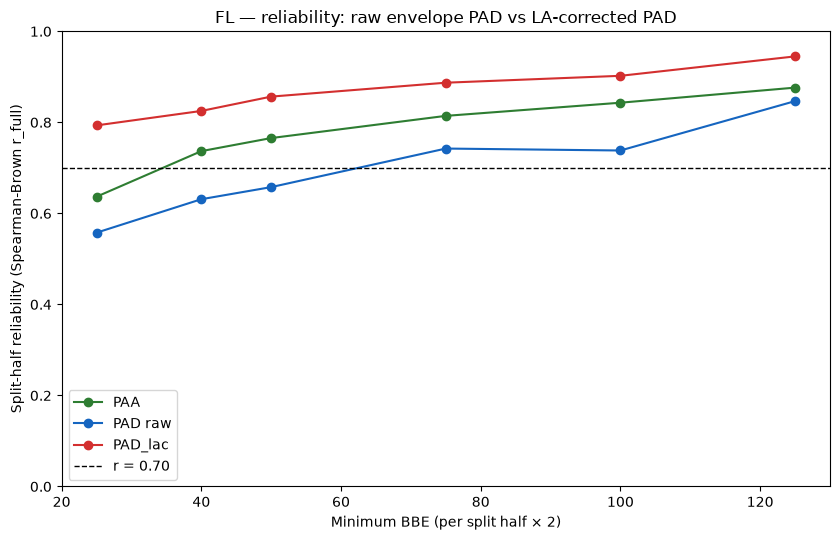

In [31]:
def build_batter_arrays(df, min_bbe):
    arrays = {}
    for (b, y), g in df.groupby(["batter", "year"]):
        gc = g.dropna(subset=["angle", "exit_speed", "spray_pull"])
        if len(gc) < min_bbe * 2:
            continue
        arrays[(b, y)] = (gc["angle"].to_numpy(),
                          gc["exit_speed"].to_numpy(),
                          gc["spray_pull"].to_numpy())
    return arrays


def _one_split(arrays, seed):
    rng = np.random.default_rng(seed)
    rows_h1, rows_h2 = [], []
    for (b, y), (la, ev, sp) in arrays.items():
        n = len(la)
        idx = rng.permutation(n)
        mid = n // 2
        i1, i2 = idx[:mid], idx[mid:]

        paa1, pad1, lac1 = compute_metrics_for_group(la[i1], ev[i1], sp[i1])
        paa2, pad2, lac2 = compute_metrics_for_group(la[i2], ev[i2], sp[i2])

        rows_h1.append((b, y, paa1, pad1, lac1))
        rows_h2.append((b, y, paa2, pad2, lac2))

    cols = ["batter", "year", "PAA", "PAD_raw", "PAD_lac"]
    h1 = pd.DataFrame(rows_h1, columns=cols)
    h2 = pd.DataFrame(rows_h2, columns=cols)
    merged = h1.merge(h2, on=["batter", "year"], suffixes=("_h1", "_h2"))

    row = {"n_batters": len(merged)}
    for metric in ["PAA", "PAD_raw", "PAD_lac"]:
        pair = merged[[f"{metric}_h1", f"{metric}_h2"]].dropna()
        if len(pair) < 10:
            row[f"{metric}_r_full"] = np.nan
            continue
        r_half = pearsonr(pair[f"{metric}_h1"], pair[f"{metric}_h2"])[0]
        row[f"{metric}_r_full"] = (2 * r_half) / (1 + r_half)
    return row


def split_half_reliability(df, n_splits=30, seed=42, min_bbe=50, n_jobs=-1):
    arrays = build_batter_arrays(df, min_bbe)
    if not arrays:
        return pd.DataFrame()
    results = Parallel(n_jobs=n_jobs)(
        delayed(_one_split)(arrays, seed + i) for i in range(n_splits)
    )
    return pd.DataFrame([r for r in results if r is not None])


# FL BBE grid — thresholds sized to a 96-game FL season
FL_BBE_GRID = [25, 40, 50, 75, 100, 125]

rel_rows = []
for k in FL_BBE_GRID:
    rel = split_half_reliability(fl, n_splits=30, min_bbe=k)
    if len(rel) == 0:
        continue
    row = {"k": k, "n_batters": rel["n_batters"].median()}
    for metric in ["PAA", "PAD_raw", "PAD_lac"]:
        row[f"{metric}_r_full"] = rel[f"{metric}_r_full"].median()
    rel_rows.append(row)
    print(f"  BBE≥{k:3d}  PAA={row['PAA_r_full']:.3f}  "
          f"PAD_raw={row['PAD_raw_r_full']:.3f}  "
          f"PAD_lac={row['PAD_lac_r_full']:.3f}  "
          f"n≈{row['n_batters']:.0f}")

rel_curve = pd.DataFrame(rel_rows)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(rel_curve["k"], rel_curve["PAA_r_full"],     "o-", label="PAA",     color="#2E7D32")
ax.plot(rel_curve["k"], rel_curve["PAD_raw_r_full"], "o-", label="PAD raw", color="#1565C0")
ax.plot(rel_curve["k"], rel_curve["PAD_lac_r_full"], "o-", label="PAD_lac", color="#D32F2F")
ax.axhline(0.70, color="black", linestyle="--", linewidth=1, label="r = 0.70")
ax.set_xlabel("Minimum BBE (per split half × 2)")
ax.set_ylabel("Split-half reliability (Spearman-Brown r_full)")
ax.set_title("FL — reliability: raw envelope PAD vs LA-corrected PAD")
ax.set_ylim(0, 1.0)
ax.legend()
plt.tight_layout(); plt.show()

## 8. Quadrant Assignment

Same median-split design; PAD_lac is now the direction feature everywhere below.

Median cuts — Pull%: 0.366   Air%: 0.571

quadrant
Neither      94
Pull only    41
Air only     41
Both         95
Name: count, dtype: int64


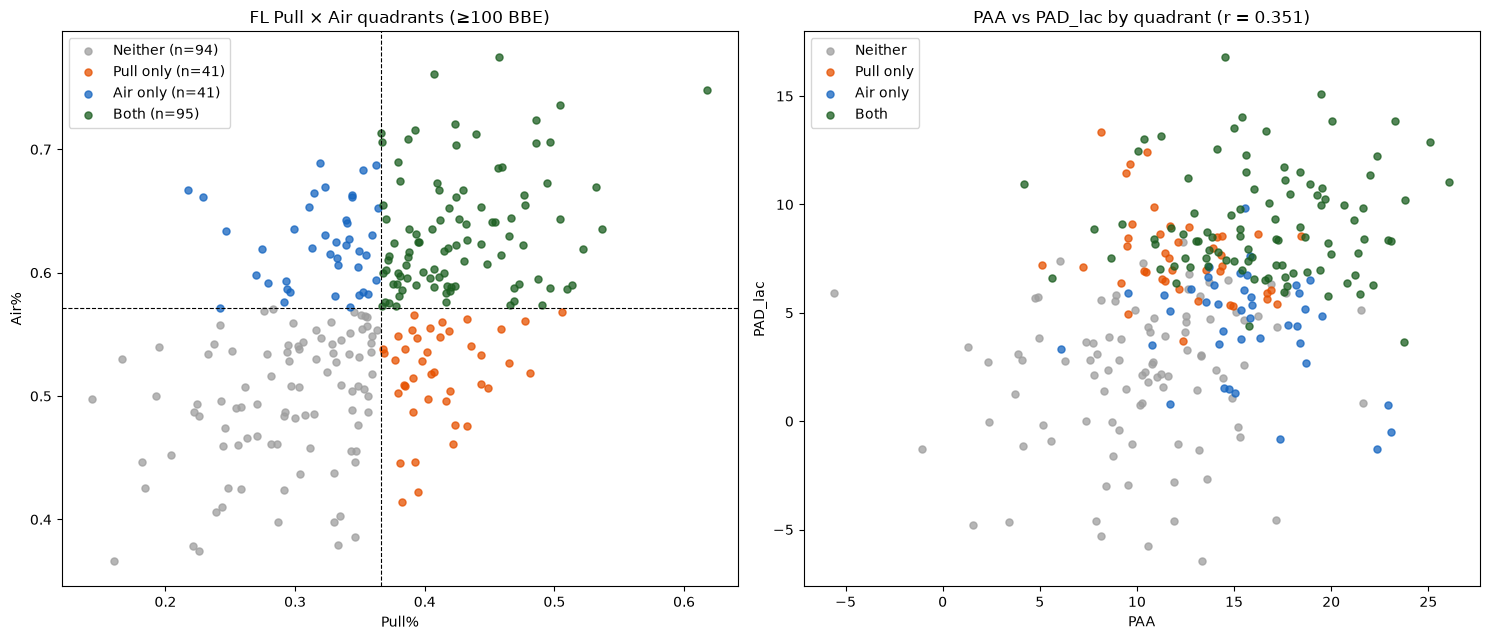

In [32]:
pull_cut = qual["pull_pct"].median()
air_cut  = qual["air_ball_pct"].median()

qual["is_pull_hitter"] = qual["pull_pct"]     >= pull_cut
qual["is_air_hitter"]  = qual["air_ball_pct"] >= air_cut

qual["quadrant"] = np.select(
    [qual["is_pull_hitter"] & qual["is_air_hitter"],
     qual["is_pull_hitter"],
     qual["is_air_hitter"]],
    ["Both", "Pull only", "Air only"],
    "Neither"
)

print(f"Median cuts — Pull%: {pull_cut:.3f}   Air%: {air_cut:.3f}\n")
print(qual["quadrant"].value_counts().reindex(QUAD_ORDER))

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

ax = axes[0]
for q in QUAD_ORDER:
    sub = qual[qual["quadrant"] == q]
    ax.scatter(sub["pull_pct"], sub["air_ball_pct"], s=26, alpha=0.75,
               color=QUAD_COLORS[q], label=f"{q} (n={len(sub)})")
ax.axvline(pull_cut, color="black", lw=0.8, ls="--")
ax.axhline(air_cut,  color="black", lw=0.8, ls="--")
ax.set_xlabel("Pull%"); ax.set_ylabel("Air%")
ax.set_title(f"FL Pull × Air quadrants (≥{MIN_BBE} BBE)")
ax.legend()

# PAA × PAD_lac space by quadrant (the separation view)
ax = axes[1]
for q in QUAD_ORDER:
    sub = qual[qual["quadrant"] == q]
    ax.scatter(sub["PAA"], sub["PAD_lac"], s=26, alpha=0.75,
               color=QUAD_COLORS[q], label=q)
r_p, _ = stats.pearsonr(qual["PAA"], qual["PAD_lac"])
ax.set_xlabel("PAA"); ax.set_ylabel("PAD_lac")
ax.set_title(f"PAA vs PAD_lac by quadrant (r = {r_p:.3f})")
ax.legend()
plt.tight_layout(); plt.show()

## 9. Correlations — PAA & PAD_lac vs the Marginals and the Joint

In [33]:
print("── Marginals & joint, batter-year level ──────────────────────────")
pairs = [("pull_pct", "air_ball_pct"), ("pull_pct", "pull_air_pct"),
         ("air_ball_pct", "pull_air_pct")]
for a, b in pairs:
    r_p, _ = stats.pearsonr(qual[a], qual[b])
    r_s, _ = spearmanr(qual[a], qual[b])
    print(f"  {a:>13} vs {b:<13}  Pearson {r_p:+.3f}   Spearman {r_s:+.3f}")

print("\n── Swing metrics vs each rate (raw PAD shown for comparison) ─────")
print(f"{'Feature':<9} {'Target':<14} {'Pearson r':>10} {'Spearman ρ':>11} {'p':>10}")
print("-" * 60)
for feat in ["PAA", "PAD_raw", "PAD_lac"]:
    for target in ["pull_pct", "air_ball_pct", "pull_air_pct"]:
        paired = qual[[feat, target]].dropna()
        r_p, _   = stats.pearsonr(paired[feat], paired[target])
        r_s, p_s = spearmanr(paired[feat], paired[target])
        print(f"{feat:<9} {target:<14} {r_p:>10.4f} {r_s:>11.4f} {p_s:>10.2e}")

── Marginals & joint, batter-year level ──────────────────────────
       pull_pct vs air_ball_pct   Pearson +0.497   Spearman +0.470
       pull_pct vs pull_air_pct   Pearson +0.871   Spearman +0.871
   air_ball_pct vs pull_air_pct   Pearson +0.720   Spearman +0.699

── Swing metrics vs each rate (raw PAD shown for comparison) ─────
Feature   Target          Pearson r  Spearman ρ          p
------------------------------------------------------------
PAA       pull_pct           0.4247      0.4111   1.78e-12
PAA       air_ball_pct       0.7047      0.7016   1.80e-41
PAA       pull_air_pct       0.5028      0.5059   5.15e-19
PAD_raw   pull_pct           0.6666      0.6406   1.06e-32
PAD_raw   air_ball_pct       0.3711      0.3499   3.19e-09
PAD_raw   pull_air_pct       0.6426      0.6262   6.55e-31
PAD_lac   pull_pct           0.9304      0.9172  1.70e-109
PAD_lac   air_ball_pct       0.5562      0.5484   1.12e-22
PAD_lac   pull_air_pct       0.8376      0.8455   2.97e-75


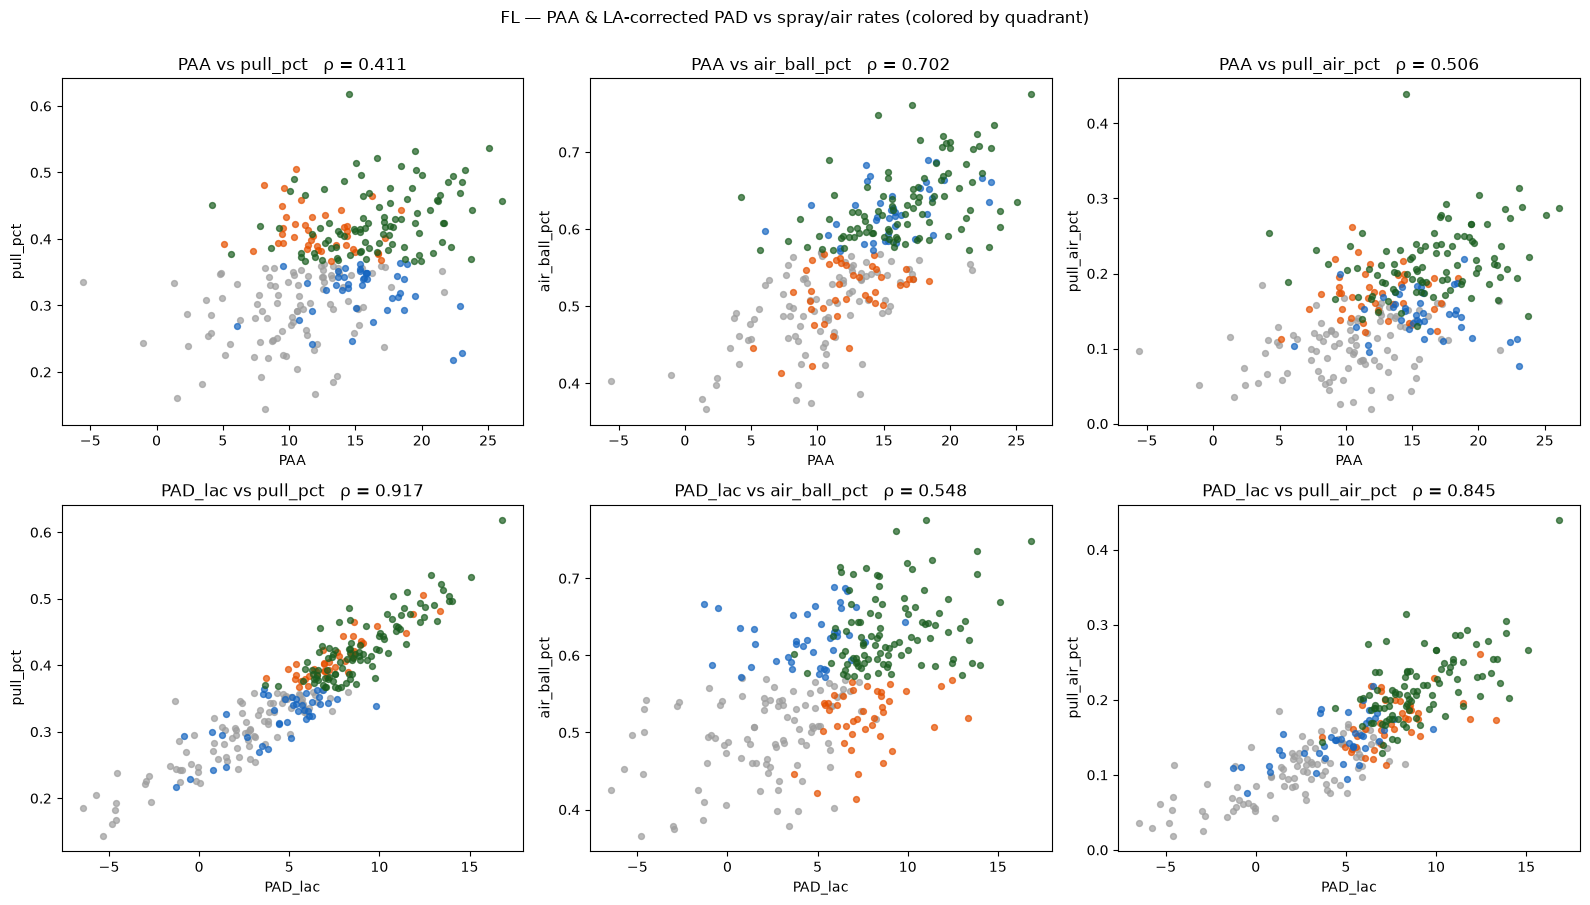

In [34]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for row, feat in enumerate(["PAA", "PAD_lac"]):
    for col, target in enumerate(["pull_pct", "air_ball_pct", "pull_air_pct"]):
        ax = axes[row, col]
        for q in QUAD_ORDER:
            sub = qual[qual["quadrant"] == q]
            ax.scatter(sub[feat], sub[target], s=18, alpha=0.7,
                       color=QUAD_COLORS[q])
        r_s, _ = spearmanr(qual[feat], qual[target])
        ax.set_xlabel(feat); ax.set_ylabel(target)
        ax.set_title(f"{feat} vs {target}   ρ = {r_s:.3f}")
plt.suptitle("FL — PAA & LA-corrected PAD vs spray/air rates (colored by quadrant)", y=1.00)
plt.tight_layout(); plt.show()

## 10. Feature Profiles by Quadrant

             PAA  PAD_lac  mean_ev   ev_90  hard_hit_pct  wOBAcon
quadrant                                                         
Neither   10.140    2.075   84.616  99.379         0.254    0.397
Pull only 12.273    7.663   86.238 101.539         0.318    0.413
Air only  15.631    4.419   86.046 100.264         0.286    0.425
Both      16.525    9.096   86.252 101.006         0.310    0.433


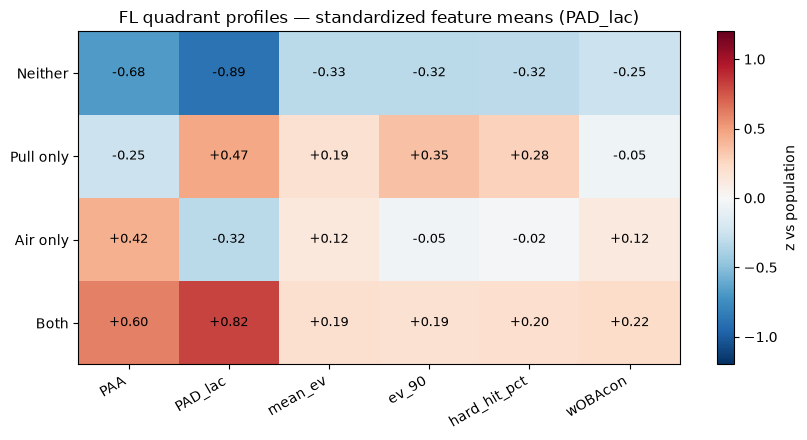

PAA: ANOVA F=43.37 (p=7.24e-23)   Kruskal H=95.97 (p=1.14e-20)
PAD_lac: ANOVA F=112.00 (p=5.73e-47)   Kruskal H=177.41 (p=3.20e-38)


In [35]:
PROFILE_FEATS = ["PAA", "PAD_lac", "mean_ev", "ev_90", "hard_hit_pct", "wOBAcon"]

feat_means = qual.groupby("quadrant")[PROFILE_FEATS].mean().reindex(QUAD_ORDER)
print(feat_means.round(3).to_string())

z = (feat_means - qual[PROFILE_FEATS].mean()) / qual[PROFILE_FEATS].std()
fig, ax = plt.subplots(figsize=(8.5, 4.5))
im = ax.imshow(z.to_numpy(dtype=np.float64), cmap="RdBu_r",
               vmin=-1.2, vmax=1.2, aspect="auto")
ax.set_xticks(range(len(PROFILE_FEATS)))
ax.set_xticklabels(PROFILE_FEATS, rotation=30, ha="right")
ax.set_yticks(range(len(QUAD_ORDER)))
ax.set_yticklabels(QUAD_ORDER)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax.text(j, i, f"{z.values[i,j]:+.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="z vs population")
ax.set_title("FL quadrant profiles — standardized feature means (PAD_lac)")
plt.tight_layout(); plt.show()

for feat in ["PAA", "PAD_lac"]:
    groups_ = [qual.loc[qual["quadrant"] == q, feat].dropna() for q in QUAD_ORDER]
    f_stat, f_p = f_oneway(*groups_)
    k_stat, k_p = kruskal(*groups_)
    print(f"{feat}: ANOVA F={f_stat:.2f} (p={f_p:.2e})   Kruskal H={k_stat:.2f} (p={k_p:.2e})")

## 11. Multinomial Quadrant Classifiers

Feature set: **PAA, PAD_lac, is_L, PAD_lac × is_L**. GroupKFold by batter.
Note from the v1 analysis: Pull only / Air only are boundary-noise categories
(both sit within ~5 points of both median cuts), so expect the extremes to
classify well and the middle classes to stay weak regardless of features —
the direct regression in §12 remains the primary deliverable.

Proportional-guess baseline accuracy: 0.289

Multinomial LR (+interaction)     accuracy 0.697   κ 0.560
Random Forest                     accuracy 0.668   κ 0.528

── Per-quadrant metrics (RF — the stronger boundary-class model in v1) ──
           precision  recall  f1-score  support
Neither        0.791   0.766     0.778   94.000
Pull only      0.484   0.366     0.417   41.000
Air only       0.400   0.390     0.395   41.000
Both           0.716   0.821     0.765   95.000


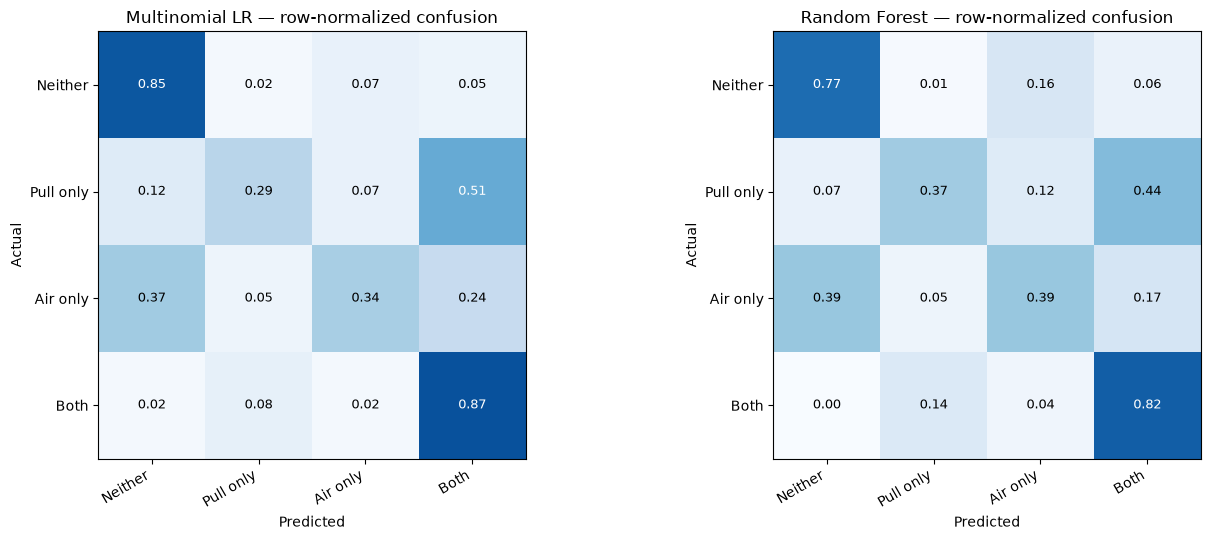

In [36]:
qual["padlac_x_isL"] = qual["PAD_lac"] * qual["is_L"]

CLF_FEATS = ["PAA", "PAD_lac", "is_L", "padlac_x_isL"]
X      = qual[CLF_FEATS].to_numpy(dtype=np.float64)
y      = qual["quadrant"].to_numpy(dtype=object)
groups = qual["batter"].to_numpy(dtype=object)

n_splits = min(5, qual["batter"].nunique())
gkf = GroupKFold(n_splits=n_splits)

pipe_lr = Pipeline([("s", StandardScaler()),
                    ("m", LogisticRegression(max_iter=2000, multi_class="multinomial"))])
pipe_rf = Pipeline([("s", StandardScaler()),
                    ("m", RandomForestClassifier(n_estimators=400, min_samples_leaf=3,
                                                 random_state=42, n_jobs=-1))])

pred_lr = cross_val_predict(pipe_lr, X, y, cv=gkf, groups=groups)
pred_rf = cross_val_predict(pipe_rf, X, y, cv=gkf, groups=groups)

class_freq = pd.Series(y).value_counts(normalize=True)
prop_baseline = (class_freq ** 2).sum()
print(f"Proportional-guess baseline accuracy: {prop_baseline:.3f}\n")

for name, pred in [("Multinomial LR (+interaction)", pred_lr), ("Random Forest", pred_rf)]:
    acc = accuracy_score(y, pred)
    kap = cohen_kappa_score(y, pred)
    print(f"{name:<32}  accuracy {acc:.3f}   κ {kap:.3f}")

print("\n── Per-quadrant metrics (RF — the stronger boundary-class model in v1) ──")
rep_rf = pd.DataFrame(classification_report(y, pred_rf, labels=QUAD_ORDER,
                                            output_dict=True, zero_division=0)).T
print(rep_rf.loc[QUAD_ORDER, ["precision", "recall", "f1-score", "support"]].round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, pred) in zip(axes, [("Multinomial LR", pred_lr), ("Random Forest", pred_rf)]):
    cm = confusion_matrix(y, pred, labels=QUAD_ORDER, normalize="true")
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(4)); ax.set_xticklabels(QUAD_ORDER, rotation=30, ha="right")
    ax.set_yticks(range(4)); ax.set_yticklabels(QUAD_ORDER)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center",
                    color="white" if cm[i,j] > 0.5 else "black", fontsize=9)
    ax.set_title(f"{name} — row-normalized confusion")
    ax.set_ylabel("Actual"); ax.set_xlabel("Predicted")
plt.tight_layout(); plt.show()

## 12. Direct Pull Air% Regression (primary deliverable)

Random Forest   R² 0.689   Spearman ρ 0.841
Linear          R² 0.748   Spearman ρ 0.873
(v1 baseline with raw PAD: Linear R² 0.547, ρ 0.719)


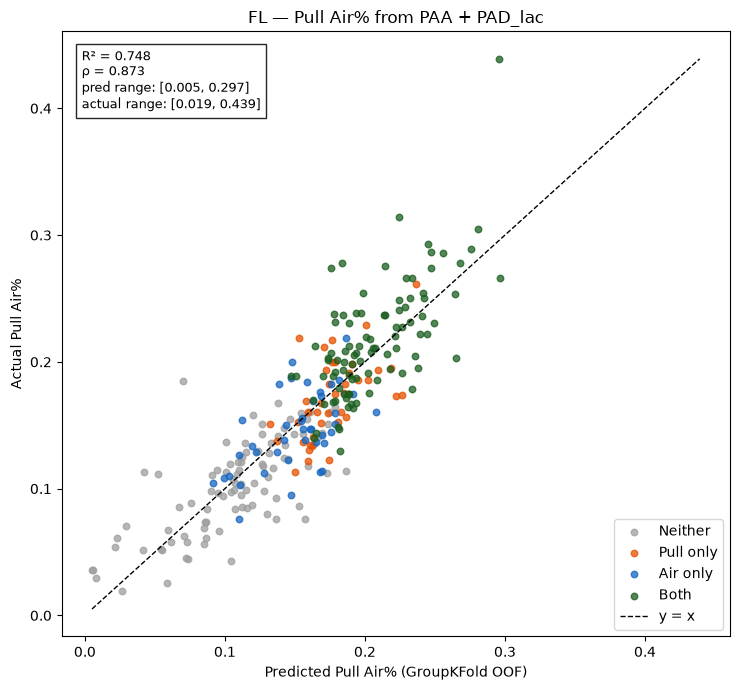

In [37]:
REG_FEATS = ["PAA", "PAD_lac", "is_L", "padlac_x_isL"]
Xr = qual[REG_FEATS].to_numpy(dtype=np.float64)
yr = qual["pull_air_pct"].to_numpy(dtype=np.float64)

pipe_reg = Pipeline([("s", StandardScaler()),
                     ("m", RandomForestRegressor(n_estimators=400, min_samples_leaf=3,
                                                 random_state=42, n_jobs=-1))])
pred_rf_reg = cross_val_predict(pipe_reg, Xr, yr, cv=gkf, groups=groups)

pipe_lin = Pipeline([("s", StandardScaler()), ("m", LinearRegression())])
pred_lin = cross_val_predict(pipe_lin, Xr, yr, cv=gkf, groups=groups)

for name, pred in [("Random Forest", pred_rf_reg), ("Linear", pred_lin)]:
    r2  = r2_score(yr, pred)
    r_s, _ = spearmanr(yr, pred)
    print(f"{name:<14}  R² {r2:.3f}   Spearman ρ {r_s:.3f}")
print("(v1 baseline with raw PAD: Linear R² 0.547, ρ 0.719)")

best_pred = pred_rf_reg if r2_score(yr, pred_rf_reg) >= r2_score(yr, pred_lin) else pred_lin
fig, ax = plt.subplots(figsize=(7.5, 7))
for q in QUAD_ORDER:
    m = qual["quadrant"].values == q
    ax.scatter(best_pred[m], yr[m], s=22, alpha=0.75, color=QUAD_COLORS[q], label=q)
lims = [min(best_pred.min(), yr.min()), max(best_pred.max(), yr.max())]
ax.plot(lims, lims, "k--", lw=1, label="y = x")
r2  = r2_score(yr, best_pred)
r_s, _ = spearmanr(yr, best_pred)
ax.text(0.03, 0.97,
        f"R² = {r2:.3f}\nρ = {r_s:.3f}\n"
        f"pred range: [{best_pred.min():.3f}, {best_pred.max():.3f}]\n"
        f"actual range: [{yr.min():.3f}, {yr.max():.3f}]",
        transform=ax.transAxes, va="top", fontsize=9,
        bbox=dict(facecolor="white", alpha=0.85))
ax.set_xlabel("Predicted Pull Air% (GroupKFold OOF)")
ax.set_ylabel("Actual Pull Air%")
ax.set_title("FL — Pull Air% from PAA + PAD_lac")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 13. wOBAcon by Quadrant

            n  wOBAcon_weighted   sem
quadrant                             
Neither    94             0.396 0.006
Pull only  41             0.417 0.012
Air only   41             0.426 0.014
Both       95             0.429 0.008


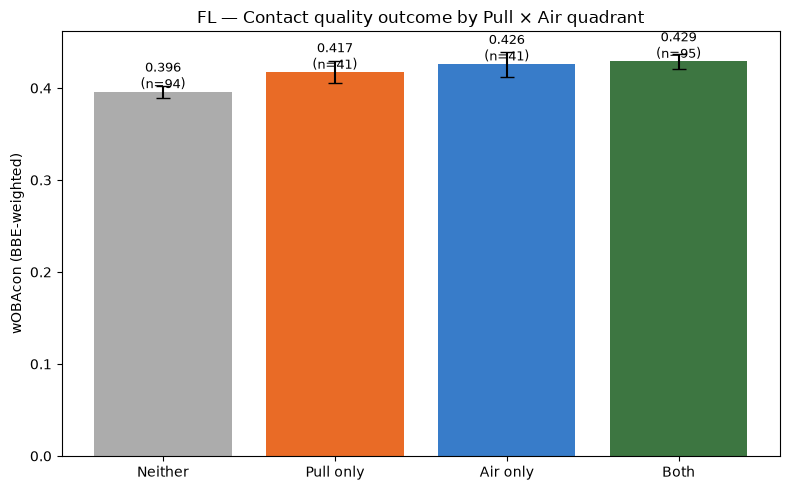

In [38]:
qd = qual.dropna(subset=["quadrant", "wOBAcon"]).copy()

rows = []
for q in QUAD_ORDER:
    sub = qd[qd["quadrant"] == q]
    weighted = np.average(sub["wOBAcon"], weights=sub["n_bbe"])
    sem      = sub["wOBAcon"].std() / np.sqrt(len(sub))
    rows.append({"quadrant": q, "n": len(sub),
                 "wOBAcon_weighted": weighted, "sem": sem})
woba_tbl = pd.DataFrame(rows).set_index("quadrant")
print(woba_tbl.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
xs = np.arange(4)
ax.bar(xs, woba_tbl["wOBAcon_weighted"], yerr=woba_tbl["sem"], capsize=5,
       color=[QUAD_COLORS[q] for q in QUAD_ORDER], alpha=0.85)
ax.set_xticks(xs); ax.set_xticklabels(QUAD_ORDER)
ax.set_ylabel("wOBAcon (BBE-weighted)")
ax.set_title("FL — Contact quality outcome by Pull × Air quadrant")
for x, (v, n) in enumerate(zip(woba_tbl["wOBAcon_weighted"], woba_tbl["n"])):
    ax.text(x, v + 0.004, f"{v:.3f}\n(n={n})", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

## 14. Year-over-Year Stickiness

Now includes PAD_lac. In v1: pull_air_pct ρ=0.725, PAA ρ=0.808, PAD_raw ρ=0.643 —
expect PAD_lac to land above PAD_raw if the MLB reliability gains transfer.

── 2025.0 → 2026.0   (n = 59 repeat batter-years) ──
   pull_air_pct   Pearson +0.778   Spearman +0.729   (p=5.91e-11)
   PAA            Pearson +0.798   Spearman +0.823   (p=1.26e-15)
   PAD_raw        Pearson +0.639   Spearman +0.584   (p=1.18e-06)
   PAD_lac        Pearson +0.824   Spearman +0.740   (p=2.19e-11)


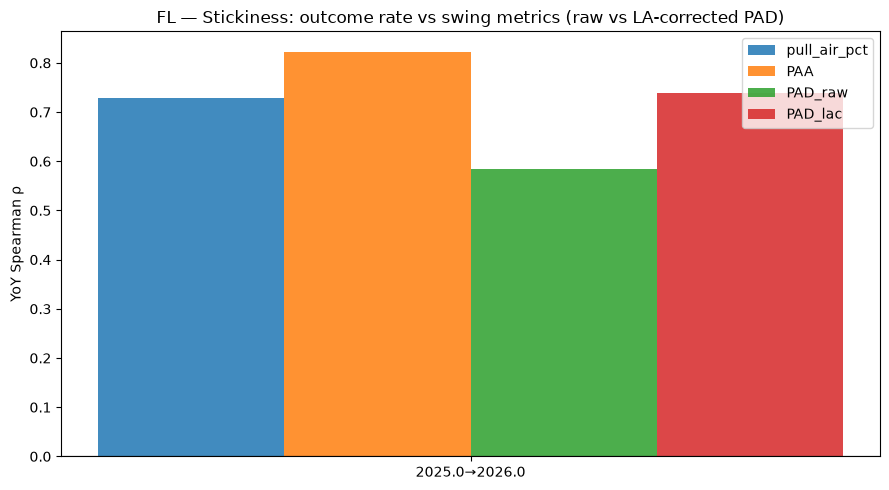

In [39]:
years = sorted(qual["year"].unique())
stick_rows = []
for y1, y2 in zip(years[:-1], years[1:]):
    a = qual[qual["year"] == y1][["batter", "pull_air_pct", "PAA", "PAD_raw", "PAD_lac"]]
    b = qual[qual["year"] == y2][["batter", "pull_air_pct", "PAA", "PAD_raw", "PAD_lac"]]
    m = a.merge(b, on="batter", suffixes=("_y1", "_y2"))
    if len(m) < 5:
        print(f"{y1}→{y2}: only {len(m)} repeaters — skipping")
        continue
    print(f"── {y1} → {y2}   (n = {len(m)} repeat batter-years) ──")
    for metric in ["pull_air_pct", "PAA", "PAD_raw", "PAD_lac"]:
        pair = m[[f"{metric}_y1", f"{metric}_y2"]].dropna()
        r_s, p_s = spearmanr(pair[f"{metric}_y1"], pair[f"{metric}_y2"])
        r_p, _   = stats.pearsonr(pair[f"{metric}_y1"], pair[f"{metric}_y2"])
        stick_rows.append({"pair": f"{y1}→{y2}", "metric": metric,
                           "pearson": r_p, "spearman": r_s, "n": len(pair)})
        print(f"   {metric:<14} Pearson {r_p:+.3f}   Spearman {r_s:+.3f}   (p={p_s:.2e})")

if stick_rows:
    stick_df = pd.DataFrame(stick_rows)
    metrics = ["pull_air_pct", "PAA", "PAD_raw", "PAD_lac"]
    pairs = stick_df["pair"].unique()
    fig, ax = plt.subplots(figsize=(9, 5))
    w = 0.2
    for i, metric in enumerate(metrics):
        sub = stick_df[stick_df["metric"] == metric]
        ax.bar(np.arange(len(pairs)) + (i - 1.5) * w, sub["spearman"], width=w,
               label=metric, alpha=0.85)
    ax.set_xticks(range(len(pairs))); ax.set_xticklabels(pairs)
    ax.set_ylabel("YoY Spearman ρ")
    ax.set_title("FL — Stickiness: outcome rate vs swing metrics (raw vs LA-corrected PAD)")
    ax.axhline(0, color="black", lw=0.8)
    ax.legend(); plt.tight_layout(); plt.show()

## 15. Plate-Discipline Profile by Quadrant

Full pitch log pull (safe bindparam expansion — names contain apostrophes).
v1 finding to re-verify: K% climbs monotonically Neither → Both (0.160 → 0.195)
despite similar overall contact rates, driven by a ~4.5-point two-strike
contact gap — Both hitters' contact quality edge erodes in full-season wOBA.

In [40]:
# ═══════════════════════════════════════════════════════════════════════════
# Section 15 — Plate-Discipline Profile by Quadrant
# ═══════════════════════════════════════════════════════════════════════════
# v1/v2 findings to verify:
#   • K% climbs monotonically Neither → Both (0.160 → 0.195) despite similar
#     OVERALL contact rate — driven by a two-strike-specific gap, not an
#     early-count gap (contact_early is nearly flat across quadrants;
#     contact_2k diverges — Both shows ~zero improvement with two strikes
#     while every other quadrant improves).
#   • Foul rate is flat overall AND flat early-vs-2k for every quadrant except
#     possibly Both — check the delta column below.
#   • Swing decisions (swing%, zone-swing%, chase%, zone_pct — both overall
#     and 2k-only) are flat or slightly LOWER for Both — ruling out an
#     approach/aggressiveness explanation.
#   • Two-strike PITCH EXPOSURE is flat across quadrants — ruling out a
#     compositional "Both just sees more 2k pitches" explanation.
#   • Whiff rate by velocity band widens specifically at the top band for
#     Both — pointing to a swing-mechanics (not decision-making) explanation.

qual_batters = qual["batter"].unique().tolist()

SQL_PITCHES = text("""
    SELECT batter, year, pitch_call, k_or_bb, play_result, strikes, balls,
           plate_x, plate_z, sz_top, sz_bot, rel_speed
    FROM pitches
    WHERE batter IN :batter_list
""").bindparams(bindparam("batter_list", expanding=True))

with engine.connect() as conn:
    pitch_log = pd.read_sql(SQL_PITCHES, conn, params={"batter_list": qual_batters})

# ── Normalize dtypes once, up front ────────────────────────────────────────────
pitch_log = pitch_log.dropna(subset=["year"]).copy()
pitch_log["year"]   = pitch_log["year"].astype("int64")
pitch_log["batter"] = pitch_log["batter"].astype(str)

qual_keys = qual[["batter", "year", "quadrant"]].copy()
qual_keys["year"]   = qual_keys["year"].astype("int64")
qual_keys["batter"] = qual_keys["batter"].astype(str)

print(f"Pulled {len(pitch_log):,} pitch rows for {pitch_log['batter'].nunique()} batters")

# ── Derive all pitch-level flags once ─────────────────────────────────────────
pitch_log["is_swing"] = pitch_log["pitch_call"].isin(
    ["strike_swinging", "foul_not_fieldable", "foul_fieldable", "foul_ball", "in_play"])
pitch_log["is_whiff"]   = pitch_log["pitch_call"] == "strike_swinging"
pitch_log["is_contact"] = pitch_log["is_swing"] & ~pitch_log["is_whiff"]
pitch_log["is_hbp"]     = pitch_log["pitch_call"] == "hit_by_pitch"
pitch_log["is_foul"]    = pitch_log["pitch_call"].isin(
    ["foul_not_fieldable", "foul_fieldable", "foul_ball"])

pitch_log["is_k"]  = pitch_log["k_or_bb"] == "strikeout"
pitch_log["is_bb"] = pitch_log["k_or_bb"] == "walk"
pitch_log["is_pa_ending"] = (
    pitch_log["is_k"] | pitch_log["is_bb"] | pitch_log["is_hbp"] |
    (pitch_log["pitch_call"] == "in_play"))

WOBA_W_FULL = {"walk": 0.751, "hit_by_pitch": 0.786,
               "single": 0.935, "double": 1.289, "triple": 1.525, "home_run": 2.146}
pitch_log["pr_norm"] = pitch_log["play_result"].astype(str).str.lower().str.replace(" ", "")
pitch_log.loc[pitch_log["is_bb"],  "pr_norm"] = "walk"
pitch_log.loc[pitch_log["is_hbp"], "pr_norm"] = "hit_by_pitch"
pitch_log["woba_val_full"] = pitch_log["pr_norm"].map(WOBA_W_FULL).fillna(0.0)

PLATE_HALF_WIDTH = 0.83  # feet, ~half of 17in plate
pitch_log["in_zone"] = (
    pitch_log["plate_x"].abs() <= PLATE_HALF_WIDTH
) & (
    pitch_log["plate_z"].between(pitch_log["sz_bot"], pitch_log["sz_top"])
)

pitch_log["velo_band"] = pd.cut(pitch_log["rel_speed"], [0, 88, 93, 100, 999],
                                labels=["<88", "88-93", "93-100", "100+"])
pitch_log["count_str"] = pitch_log["balls"].astype(str) + "-" + pitch_log["strikes"].astype(str)

non_two_strike = pitch_log[pitch_log["strikes"] < 2]
two_strike     = pitch_log[pitch_log["strikes"] == 2]

pa_ending = pitch_log[pitch_log["is_pa_ending"]]


# ── K% / BB% / contact% / wOBA (overall) ──────────────────────────────────────
perf = pitch_log.groupby(["batter", "year"]).agg(
    n_swings  = ("is_swing",   "sum"),
    n_contact = ("is_contact", "sum"),
).reset_index()
pa_agg = pa_ending.groupby(["batter", "year"]).agg(
    n_pa = ("is_pa_ending", "sum"),
    n_k  = ("is_k",  "sum"),
    n_bb = ("is_bb", "sum"),
    wOBA = ("woba_val_full", "mean"),
).reset_index()
perf = perf.merge(pa_agg, on=["batter", "year"], how="left")
perf["k_pct"]       = perf["n_k"]  / perf["n_pa"]
perf["bb_pct"]      = perf["n_bb"] / perf["n_pa"]
perf["contact_pct"] = perf["n_contact"] / perf["n_swings"]

# ── Contact rate: early counts vs two-strike counts ───────────────────────────
contact_early = (
    non_two_strike[non_two_strike["is_swing"]]
    .groupby(["batter", "year"])
    .agg(n_swings_early=("is_swing", "size"), contact_early=("is_contact", "mean"))
    .reset_index()
)
contact_2k = (
    two_strike[two_strike["is_swing"]]
    .groupby(["batter", "year"])
    .agg(n_swings_2k=("is_swing", "size"), contact_2k=("is_contact", "mean"))
    .reset_index()
)

# ── Contact rate: early counts vs two-strike counts ───────────────────────────
contact_early = (
    non_two_strike[non_two_strike["is_swing"]]
    .groupby(["batter", "year"])
    .agg(n_swings_early=("is_swing", "size"), contact_early=("is_contact", "mean"))
    .reset_index()
)
contact_2k = (
    two_strike[two_strike["is_swing"]]
    .groupby(["batter", "year"])
    .agg(n_swings_2k_contact=("is_swing", "size"), contact_2k=("is_contact", "mean"))  # renamed
    .reset_index()
)
perf = perf.merge(contact_early, on=["batter", "year"], how="left")
perf = perf.merge(contact_2k, on=["batter", "year"], how="left")

# ── Foul share: early vs two-strike ────────────────────────────────────────────
foul_early = (
    non_two_strike[non_two_strike["is_contact"]]
    .groupby(["batter", "year"])
    .agg(n_contact_early=("is_contact", "size"), foul_share_early=("is_foul", "mean"))
    .reset_index()
)
foul_2k = (
    two_strike[two_strike["is_contact"]]
    .groupby(["batter", "year"])
    .agg(n_contact_2k_f=("is_contact", "size"), foul_share_2k=("is_foul", "mean"))
    .reset_index()
)
perf = perf.merge(foul_early, on=["batter", "year"], how="left")
perf = perf.merge(foul_2k, on=["batter", "year"], how="left")

# ── Swing / zone-swing / chase (overall) ──────────────────────────────────────
def swing_decision_metrics(df, suffix=""):
    base = df.groupby(["batter", "year"]).agg(
        **{f"n_pitches{suffix}": ("pitch_call", "size"),
           f"n_swings{suffix}":  ("is_swing", "sum"),
           f"n_in_zone{suffix}": ("in_zone", "sum")}
    ).reset_index()
    zone_sw = (df[df["in_zone"]].groupby(["batter", "year"])
              .agg(**{f"n_zone_swings{suffix}": ("is_swing", "sum")}).reset_index())
    chase_sw = (df[~df["in_zone"]].groupby(["batter", "year"])
               .agg(**{f"n_chase_swings{suffix}": ("is_swing", "sum"),
                       f"n_out_zone{suffix}":     ("in_zone", "size")}).reset_index())
    out = base.merge(zone_sw, on=["batter", "year"], how="left").merge(
        chase_sw, on=["batter", "year"], how="left")
    out[f"swing_pct{suffix}"]      = out[f"n_swings{suffix}"] / out[f"n_pitches{suffix}"]
    out[f"zone_swing_pct{suffix}"] = out[f"n_zone_swings{suffix}"] / out[f"n_in_zone{suffix}"]
    out[f"chase_pct{suffix}"]      = out[f"n_chase_swings{suffix}"] / out[f"n_out_zone{suffix}"]
    out[f"zone_pct{suffix}"]       = out[f"n_in_zone{suffix}"] / out[f"n_pitches{suffix}"]
    return out

swing_overall = swing_decision_metrics(pitch_log)
swing_2k      = swing_decision_metrics(two_strike, suffix="_2k")
perf = perf.merge(swing_overall, on=["batter", "year"], how="left")
perf = perf.merge(swing_2k, on=["batter", "year"], how="left")

# ── Two-strike pitch exposure (compositional check) ───────────────────────────
reaches_2k = pitch_log.groupby(["batter", "year"]).agg(
    n_pitches_total = ("pitch_call", "size"),
    n_2k_pitches    = ("strikes", lambda s: (s == 2).sum())
).reset_index()
reaches_2k["pct_pitches_2k"] = reaches_2k["n_2k_pitches"] / reaches_2k["n_pitches_total"]
perf = perf.merge(reaches_2k[["batter", "year", "pct_pitches_2k"]], on=["batter", "year"], how="left")

# ── Whiff rate by velocity band, two-strike swings only ──────────────────────
whiff_by_velo = (
    two_strike[two_strike["is_swing"]]
    .merge(qual_keys, on=["batter", "year"])
    .groupby(["quadrant", "velo_band"], observed=True)
    .agg(n_swings=("is_swing", "size"), whiff_pct=("is_whiff", "mean"))
    .reset_index()
    .pivot(index="quadrant", columns="velo_band", values="whiff_pct")
    .reindex(QUAD_ORDER)
)
whiff_by_velo_early = (
    non_two_strike[non_two_strike["is_swing"]]
    .merge(qual_keys, on=["batter", "year"])
    .groupby(["quadrant", "velo_band"], observed=True)
    .agg(n_swings=("is_swing", "size"), whiff_pct=("is_whiff", "mean"))
    .reset_index()
    .pivot(index="quadrant", columns="velo_band", values="whiff_pct")
    .reindex(QUAD_ORDER)
)

# ── Count distribution ─────────────────────────────────────────────────────────
count_dist = (
    pitch_log.merge(qual_keys, on=["batter", "year"])
    .groupby(["quadrant", "count_str"]).size().reset_index(name="n")
)
count_dist["pct"] = count_dist.groupby("quadrant")["n"].transform(lambda s: s / s.sum())
count_order = ["0-0","1-0","0-1","2-0","1-1","0-2","3-0","2-1","1-2","3-1","2-2","3-2"]
count_pivot = (
    count_dist.pivot(index="count_str", columns="quadrant", values="pct")
    .reindex(QUAD_ORDER, axis=1)
    .reindex([c for c in count_order if c in count_dist["count_str"].values])
)

# ── Merge everything onto qual and aggregate by quadrant ──────────────────────
quad_perf = qual.merge(perf, on=["batter", "year"], how="left")

def wavg(g, col, weight_col):
    sub = g[[col, weight_col]].dropna()
    return np.average(sub[col], weights=sub[weight_col]) if len(sub) else np.nan

profile_by_quad = quad_perf.groupby("quadrant").apply(
    lambda g: pd.Series({
        "n":               len(g),
        "k_pct":           wavg(g, "k_pct", "n_pa"),
        "bb_pct":          wavg(g, "bb_pct", "n_pa"),
        "contact_pct":     wavg(g, "contact_pct", "n_pa"),
        "contact_early":   wavg(g, "contact_early", "n_swings_early"),
        "contact_2k":      wavg(g, "contact_2k", "n_swings_2k_contact"),
        "wOBA":            wavg(g, "wOBA", "n_pa"),
        "foul_share_early":wavg(g, "foul_share_early", "n_contact_early"),
        "foul_share_2k":   wavg(g, "foul_share_2k", "n_contact_2k_f"),
        "swing_pct":       wavg(g, "swing_pct", "n_pitches"),
        "zone_swing_pct":  wavg(g, "zone_swing_pct", "n_pitches"),
        "chase_pct":       wavg(g, "chase_pct", "n_pitches"),
        "zone_pct":        wavg(g, "zone_pct", "n_pitches"),
        "swing_pct_2k":    wavg(g, "swing_pct_2k", "n_pitches_2k"),
        "zone_swing_pct_2k": wavg(g, "zone_swing_pct_2k", "n_pitches_2k"),
        "chase_pct_2k":    wavg(g, "chase_pct_2k", "n_pitches_2k"),
        "zone_pct_2k":     wavg(g, "zone_pct_2k", "n_pitches_2k"),
        "pct_pitches_2k":  g["pct_pitches_2k"].mean(),
    })
).reindex(QUAD_ORDER)

profile_by_quad["contact_delta"] = profile_by_quad["contact_2k"] - profile_by_quad["contact_early"]
profile_by_quad["foul_delta"]    = profile_by_quad["foul_share_2k"] - profile_by_quad["foul_share_early"]

print("\n── Plate-discipline profile by quadrant ──")
print(profile_by_quad.round(3).to_string())

print("\n── Count distribution by quadrant ──")
print(count_pivot.round(3).to_string())

print("\n── Whiff rate by velocity band — two-strike swings ──")
print(whiff_by_velo.round(3).to_string())

print("\n── Whiff rate by velocity band — early-count swings (comparison) ──")
print(whiff_by_velo_early.round(3).to_string())

Pulled 304,547 pitch rows for 212 batters

── Plate-discipline profile by quadrant ──
               n  k_pct  bb_pct  contact_pct  contact_early  contact_2k  wOBA  foul_share_early  foul_share_2k  swing_pct  zone_swing_pct  chase_pct  zone_pct  swing_pct_2k  zone_swing_pct_2k  chase_pct_2k  zone_pct_2k  pct_pitches_2k  contact_delta  foul_delta
quadrant                                                                                                                                                                                                                                                             
Neither   94.000  0.160   0.105        0.806          0.802       0.808 0.362             0.469          0.481      0.450           0.677      0.284     0.421         0.600              0.902         0.422        0.371           0.269          0.006       0.012
Pull only 41.000  0.174   0.095        0.768          0.763       0.770 0.368             0.448          0.456      0.454       

## 16. Final Deliverable

In [41]:
out = qual[["batter", "year", "stand", "n_bbe",
            "pull_pct", "air_ball_pct", "pull_air_pct",
            "PAA", "PAD_raw", "PAD_lac", "quadrant",
            "mean_ev", "ev_90", "hard_hit_pct", "wOBAcon"]].copy()
out["pred_pull_air_pct"] = best_pred
out = out.merge(
    quad_perf[["batter", "year", "k_pct", "bb_pct", "contact_pct", "contact_2k", "wOBA"]],
    on=["batter", "year"], how="left")
out = out.sort_values("pull_air_pct", ascending=False).reset_index(drop=True)

print("── Top 15 by Pull Air% ──")
print(out.head(15).to_string(index=False))

Path("output").mkdir(exist_ok=True)
out.to_csv("output/fl_pull_air_quadrants_v2.csv", index=False)
print(f"\nSaved → output/fl_pull_air_quadrants_v2.csv   ({len(out)} batter-years)")

── Top 15 by Pull Air% ──
             batter     year stand   n_bbe  pull_pct  air_ball_pct  pull_air_pct    PAA  PAD_raw  PAD_lac quadrant  mean_ev   ev_90  hard_hit_pct  wOBAcon  pred_pull_air_pct  k_pct  bb_pct  contact_pct  contact_2k  wOBA
      Curbelo, Luis 2025.000     R 123.000     0.618         0.748         0.439 14.529   35.151   16.822     Both   85.526 103.329         0.350    0.457              0.296  0.219   0.128        0.760       0.756 0.381
      Baker, Dillon 2026.000     R 105.000     0.486         0.705         0.314 23.059    9.877    8.312     Both   82.930  96.692         0.200    0.460              0.224  0.260   0.110        0.715       0.765 0.387
       Pino, Yassel 2025.000     R 272.000     0.496         0.706         0.305 20.025   18.906   13.865     Both   87.347 100.920         0.298    0.412              0.281  0.176   0.064        0.751       0.716 0.361
        Vogel, Ryan 2025.000     R 174.000     0.477         0.655         0.293 17.578   16.0

In [42]:
# ── Foul ball rate by quadrant ────────────────────────────────────────────────
pitch_log["is_foul"] = pitch_log["pitch_call"].isin(
    ["foul_not_fieldable", "foul_fieldable", "foul_ball"]
)

foul_perf = (
    pitch_log[pitch_log["is_contact"]]
    .groupby(["batter", "year"])
    .agg(n_contact_foul=("is_contact", "size"), foul_share=("is_foul", "mean"))  # renamed
    .reset_index()
)

quad_perf = quad_perf.drop(columns=["n_contact_foul", "foul_share"], errors="ignore")
quad_perf = quad_perf.merge(foul_perf, on=["batter", "year"], how="left")

foul_by_quad = quad_perf.groupby("quadrant").apply(
    lambda g: pd.Series({
        "n": len(g),
        "foul_share": np.average(
            g["foul_share"].dropna(),
            weights=g.loc[g["foul_share"].notna(), "n_contact_foul"]),  # updated
    })
).reindex(QUAD_ORDER)

print(foul_by_quad.round(3).to_string())

               n  foul_share
quadrant                    
Neither   94.000       0.473
Pull only 41.000       0.451
Air only  41.000       0.490
Both      95.000       0.488


In [43]:
dupes = quad_perf.columns[quad_perf.columns.duplicated()].tolist()
print("Duplicated columns:", dupes)

suffix_cols = [c for c in quad_perf.columns if c.endswith("_x") or c.endswith("_y")]
print("Suffix-collision columns:", suffix_cols)

Duplicated columns: []
Suffix-collision columns: ['n_swings_x', 'n_swings_y']


In [44]:
# ── Reset: rebuild quad_perf clean from qual before running the consolidated cell ──
del quad_perf  # remove whatever accumulated state exists

In [45]:
# ── Rebuild quad_perf clean ────────────────────────────────────────────────────
quad_perf = qual.copy()

quad_perf = quad_perf.merge(perf, on=["batter", "year"], how="left")

# Now merge swing_perf — drop any overlapping names first
overlap = [c for c in swing_perf.columns if c in quad_perf.columns and c not in ["batter", "year"]]
quad_perf = quad_perf.drop(columns=overlap, errors="ignore")
quad_perf = quad_perf.merge(swing_perf, on=["batter", "year"], how="left")

swing_by_quad = quad_perf.groupby("quadrant").apply(
    lambda g: pd.Series({
        "n":              len(g),
        "swing_pct":      np.average(g["swing_pct"].dropna(),      weights=g.loc[g["swing_pct"].notna(), "n_pitches"]),
        "zone_swing_pct": np.average(g["zone_swing_pct"].dropna(), weights=g.loc[g["zone_swing_pct"].notna(), "n_pitches"]),
        "chase_pct":      np.average(g["chase_pct"].dropna(),      weights=g.loc[g["chase_pct"].notna(), "n_pitches"]),
        "zone_pct":       np.average(g["zone_pct"].dropna(),       weights=g.loc[g["zone_pct"].notna(), "n_pitches"]),
    })
).reindex(QUAD_ORDER)

print(swing_by_quad.round(3).to_string())

NameError: name 'swing_perf' is not defined

In [ ]:
# ── Swing rate, zone-swing rate, and chase rate by quadrant ──────────────────
# Requires plate location to separate in-zone from out-of-zone swings.
# If you don't already have plate_x/plate_z/sz_top/sz_bot in pitch_log, pull them:

SQL_LOC = text("""
    SELECT batter, year, pitch_call, k_or_bb, play_result, strikes,
           plate_x, plate_z, sz_top, sz_bot, balls
    FROM pitches
    WHERE batter IN :batter_list
""").bindparams(bindparam("batter_list", expanding=True))

with engine.connect() as conn:
    pitch_log = pd.read_sql(SQL_LOC, conn, params={"batter_list": qual_batters})

pitch_log = pitch_log.dropna(subset=["year"]).copy()
pitch_log["year"] = pitch_log["year"].astype(int)

# Re-derive swing/contact/whiff flags (same as before)
pitch_log["is_swing"] = pitch_log["pitch_call"].isin(
    ["strike_swinging", "foul_not_fieldable", "foul_fieldable", "foul_ball", "in_play"])
pitch_log["is_whiff"]   = pitch_log["pitch_call"] == "strike_swinging"
pitch_log["is_contact"] = pitch_log["is_swing"] & ~pitch_log["is_whiff"]

# Zone membership: standard heart-of-plate width (~8.5 in half-width = 17in plate)
PLATE_HALF_WIDTH = 0.83  # feet, ~half of 17in plate
pitch_log["in_zone"] = (
    pitch_log["plate_x"].abs() <= PLATE_HALF_WIDTH
) & (
    pitch_log["plate_z"].between(pitch_log["sz_bot"], pitch_log["sz_top"])
)

swing_perf = pitch_log.groupby(["batter", "year"]).agg(
    n_pitches   = ("pitch_call", "size"),
    n_swings    = ("is_swing",   "sum"),
    n_in_zone   = ("in_zone",    "sum"),
).reset_index()

zone_swings = (
    pitch_log[pitch_log["in_zone"]]
    .groupby(["batter", "year"])
    .agg(n_zone_swings=("is_swing", "sum"))
    .reset_index()
)
chase_swings = (
    pitch_log[~pitch_log["in_zone"]]
    .groupby(["batter", "year"])
    .agg(n_chase_swings=("is_swing", "sum"), n_out_zone=("in_zone", "size"))
    .reset_index()
)

swing_perf = (swing_perf
    .merge(zone_swings, on=["batter", "year"], how="left")
    .merge(chase_swings, on=["batter", "year"], how="left"))

swing_perf["swing_pct"]       = swing_perf["n_swings"] / swing_perf["n_pitches"]
swing_perf["zone_swing_pct"]  = swing_perf["n_zone_swings"] / swing_perf["n_in_zone"]
swing_perf["chase_pct"]       = swing_perf["n_chase_swings"] / swing_perf["n_out_zone"]
swing_perf["zone_pct"]        = swing_perf["n_in_zone"] / swing_perf["n_pitches"]

quad_perf = quad_perf.merge(
    swing_perf[["batter", "year", "swing_pct", "zone_swing_pct", "chase_pct", "zone_pct", "n_pitches"]],
    on=["batter", "year"], how="left"
)

swing_by_quad = quad_perf.groupby("quadrant").apply(
    lambda g: pd.Series({
        "n": len(g),
        "swing_pct":      np.average(g["swing_pct"].dropna(),      weights=g.loc[g["swing_pct"].notna(), "n_pitches"]),
        "zone_swing_pct": np.average(g["zone_swing_pct"].dropna(), weights=g.loc[g["zone_swing_pct"].notna(), "n_pitches"]),
        "chase_pct":      np.average(g["chase_pct"].dropna(),      weights=g.loc[g["chase_pct"].notna(), "n_pitches"]),
        "zone_pct":       np.average(g["zone_pct"].dropna(),       weights=g.loc[g["zone_pct"].notna(), "n_pitches"]),
    })
).reindex(QUAD_ORDER)

print(swing_by_quad.round(3).to_string())

KeyError: 'swing_pct'

In [ ]:
# ── Same swing-decision metrics, but restricted to two-strike counts ────────
two_strike_pitches = pitch_log[pitch_log["strikes"] == 2].copy()

swing_2k = two_strike_pitches.groupby(["batter", "year"]).agg(
    n_pitches_2k  = ("pitch_call", "size"),
    n_swings_2k   = ("is_swing",   "sum"),
    n_in_zone_2k  = ("in_zone",    "sum"),
).reset_index()

zone_swings_2k = (
    two_strike_pitches[two_strike_pitches["in_zone"]]
    .groupby(["batter", "year"])
    .agg(n_zone_swings_2k=("is_swing", "sum"))
    .reset_index()
)
chase_swings_2k = (
    two_strike_pitches[~two_strike_pitches["in_zone"]]
    .groupby(["batter", "year"])
    .agg(n_chase_swings_2k=("is_swing", "sum"), n_out_zone_2k=("in_zone", "size"))
    .reset_index()
)

swing_2k = (swing_2k
    .merge(zone_swings_2k, on=["batter", "year"], how="left")
    .merge(chase_swings_2k, on=["batter", "year"], how="left"))

swing_2k["swing_pct_2k"]      = swing_2k["n_swings_2k"] / swing_2k["n_pitches_2k"]
swing_2k["zone_swing_pct_2k"] = swing_2k["n_zone_swings_2k"] / swing_2k["n_in_zone_2k"]
swing_2k["chase_pct_2k"]      = swing_2k["n_chase_swings_2k"] / swing_2k["n_out_zone_2k"]
swing_2k["zone_pct_2k"]       = swing_2k["n_in_zone_2k"] / swing_2k["n_pitches_2k"]

quad_perf = quad_perf.merge(
    swing_2k[["batter", "year", "swing_pct_2k", "zone_swing_pct_2k", "chase_pct_2k", "zone_pct_2k", "n_pitches_2k"]],
    on=["batter", "year"], how="left"
)

swing_2k_by_quad = quad_perf.groupby("quadrant").apply(
    lambda g: pd.Series({
        "n": len(g),
        "swing_pct_2k":      np.average(g["swing_pct_2k"].dropna(),      weights=g.loc[g["swing_pct_2k"].notna(), "n_pitches_2k"]),
        "zone_swing_pct_2k": np.average(g["zone_swing_pct_2k"].dropna(), weights=g.loc[g["zone_swing_pct_2k"].notna(), "n_pitches_2k"]),
        "chase_pct_2k":      np.average(g["chase_pct_2k"].dropna(),      weights=g.loc[g["chase_pct_2k"].notna(), "n_pitches_2k"]),
        "zone_pct_2k":       np.average(g["zone_pct_2k"].dropna(),       weights=g.loc[g["zone_pct_2k"].notna(), "n_pitches_2k"]),
    })
).reindex(QUAD_ORDER)

print(swing_2k_by_quad.round(3).to_string())

KeyError: 'swing_pct_2k'

In [ ]:
# ── Whiff rate on swings, by pitch velocity band and count pressure ──────────
# Requires rel_speed; add to the SELECT if not already present
SQL_VELO = text("""
    SELECT batter, year, pitch_call, strikes, rel_speed
    FROM pitches
    WHERE batter IN :batter_list
""").bindparams(bindparam("batter_list", expanding=True))

with engine.connect() as conn:
    velo_log = pd.read_sql(SQL_VELO, conn, params={"batter_list": qual_batters})

velo_log = velo_log.dropna(subset=["year"]).copy()
velo_log["year"] = velo_log["year"].astype(int)
velo_log["is_swing"] = velo_log["pitch_call"].isin(
    ["strike_swinging", "foul_not_fieldable", "foul_fieldable", "foul_ball", "in_play"])
velo_log["is_whiff"] = velo_log["pitch_call"] == "strike_swinging"

velo_log["velo_band"] = pd.cut(velo_log["rel_speed"], [0, 88, 93, 100, 999],
                               labels=["<88", "88-93", "93-100", "100+"])

whiff_by_velo = (
    velo_log[velo_log["is_swing"] & (velo_log["strikes"] == 2)]
    .merge(qual[["batter", "year", "quadrant"]], on=["batter", "year"])
    .groupby(["quadrant", "velo_band"], observed=True)
    .agg(n_swings=("is_swing", "size"), whiff_pct=("is_whiff", "mean"))
    .reset_index()
    .pivot(index="quadrant", columns="velo_band", values="whiff_pct")
    .reindex(QUAD_ORDER)
)
print(whiff_by_velo.round(3).to_string())

velo_band   <88  88-93  93-100
quadrant                      
Neither   0.215  0.150   0.212
Pull only 0.252  0.183   0.227
Air only  0.230  0.178   0.219
Both      0.257  0.192   0.259


In [ ]:
# ── Contact rate in 0-1 strike counts only, for comparison ──────────────────
non_two_strike = pitch_log[pitch_log["strikes"] < 2]

contact_early = non_two_strike[non_two_strike["is_swing"]].groupby(["batter", "year"]).agg(
    n_swings_early=("is_swing", "size"), contact_early=("is_contact", "mean")
).reset_index()

quad_perf = quad_perf.merge(contact_early, on=["batter", "year"], how="left")

early_by_quad = quad_perf.groupby("quadrant").apply(
    lambda g: pd.Series({
        "n": len(g),
        "contact_early": np.average(g["contact_early"].dropna(),
                                    weights=g.loc[g["contact_early"].notna(), "n_swings_early"]),
    })
).reindex(QUAD_ORDER)
print(early_by_quad.round(3).to_string())

KeyError: 'contact_early'

In [ ]:

# ── Pull pitch log with counts + zone location ──────────────────────────────
SQL_COUNTS = text("""
    SELECT batter, year, pitch_call, k_or_bb, play_result, strikes, balls,
           plate_x, plate_z, sz_top, sz_bot
    FROM pitches
    WHERE batter IN :batter_list
""").bindparams(bindparam("batter_list", expanding=True))

with engine.connect() as conn:
    pitch_log = pd.read_sql(SQL_COUNTS, conn, params={"batter_list": qual_batters})

# ── Normalize dtypes once, up front (avoids the pyarrow/merge-mismatch issue) ──
pitch_log = pitch_log.dropna(subset=["year"]).copy()
pitch_log["year"]   = pitch_log["year"].astype("int64")
pitch_log["batter"] = pitch_log["batter"].astype(str)

qual_keys = qual[["batter", "year", "quadrant"]].copy()
qual_keys["year"]   = qual_keys["year"].astype("int64")
qual_keys["batter"] = qual_keys["batter"].astype(str)

# ── Derive all flags once ─────────────────────────────────────────────────────
pitch_log["is_swing"] = pitch_log["pitch_call"].isin(
    ["strike_swinging", "foul_not_fieldable", "foul_fieldable", "foul_ball", "in_play"])
pitch_log["is_whiff"]   = pitch_log["pitch_call"] == "strike_swinging"
pitch_log["is_contact"] = pitch_log["is_swing"] & ~pitch_log["is_whiff"]
pitch_log["is_foul"]    = pitch_log["pitch_call"].isin(
    ["foul_not_fieldable", "foul_fieldable", "foul_ball"])

PLATE_HALF_WIDTH = 0.83
pitch_log["in_zone"] = (
    pitch_log["plate_x"].abs() <= PLATE_HALF_WIDTH
) & (
    pitch_log["plate_z"].between(pitch_log["sz_bot"], pitch_log["sz_top"])
)

pitch_log["count_str"] = pitch_log["balls"].astype(str) + "-" + pitch_log["strikes"].astype(str)
non_two_strike = pitch_log[pitch_log["strikes"] < 2]

print(f"Pulled {len(pitch_log):,} pitch rows for {pitch_log['batter'].nunique()} batters")


# ── 1. Count distribution by quadrant ─────────────────────────────────────────
count_dist = (
    pitch_log.merge(qual_keys, on=["batter", "year"])
    .groupby(["quadrant", "count_str"]).size().reset_index(name="n")
)
count_dist["pct"] = count_dist.groupby("quadrant")["n"].transform(lambda s: s / s.sum())

count_order = ["0-0","1-0","0-1","2-0","1-1","0-2","3-0","2-1","1-2","3-1","2-2","3-2"]
count_pivot = (
    count_dist.pivot(index="count_str", columns="quadrant", values="pct")
    .reindex(QUAD_ORDER, axis=1)
    .reindex([c for c in count_order if c in count_dist["count_str"].values])
)
print("\n── Count distribution by quadrant ──")
print(count_pivot.round(3).to_string())


# ── 2. Two-strike exposure ────────────────────────────────────────────────────
reaches_2k = pitch_log.groupby(["batter", "year"]).agg(
    n_pitches    = ("pitch_call", "size"),
    n_2k_pitches = ("strikes", lambda s: (s == 2).sum())
).reset_index()
reaches_2k["pct_pitches_2k"] = reaches_2k["n_2k_pitches"] / reaches_2k["n_pitches"]

quad_perf = quad_perf.drop(columns=["pct_pitches_2k"], errors="ignore")
quad_perf = quad_perf.merge(
    reaches_2k[["batter", "year", "pct_pitches_2k"]], on=["batter", "year"], how="left"
)

reach_by_quad = quad_perf.groupby("quadrant")["pct_pitches_2k"].mean().reindex(QUAD_ORDER)
print("\n── Share of all pitches seen at two strikes ──")
print(reach_by_quad.round(3).to_string())


# ── 3. Foul share: early vs two-strike ────────────────────────────────────────
foul_early = (
    non_two_strike[non_two_strike["is_contact"]]
    .groupby(["batter", "year"])
    .agg(n_contact_early=("is_contact", "size"), foul_share_early=("is_foul", "mean"))
    .reset_index()
)
foul_2k = (
    pitch_log[(pitch_log["strikes"] == 2) & pitch_log["is_contact"]]
    .groupby(["batter", "year"])
    .agg(n_contact_2k=("is_contact", "size"), foul_share_2k=("is_foul", "mean"))
    .reset_index()
)

quad_perf = quad_perf.drop(columns=["n_contact_early", "foul_share_early"], errors="ignore")
quad_perf = quad_perf.merge(foul_early, on=["batter", "year"], how="left")
quad_perf = quad_perf.drop(columns=["n_contact_2k", "foul_share_2k"], errors="ignore")
quad_perf = quad_perf.merge(foul_2k, on=["batter", "year"], how="left")

foul_split_by_quad = quad_perf.groupby("quadrant").apply(
    lambda g: pd.Series({
        "foul_share_early": np.average(
            g["foul_share_early"].dropna(),
            weights=g.loc[g["foul_share_early"].notna(), "n_contact_early"]),
        "foul_share_2k": np.average(
            g["foul_share_2k"].dropna(),
            weights=g.loc[g["foul_share_2k"].notna(), "n_contact_2k"]),
    })
).reindex(QUAD_ORDER)
foul_split_by_quad["delta"] = foul_split_by_quad["foul_share_2k"] - foul_split_by_quad["foul_share_early"]

print("\n── Foul share: early vs two-strike ──")
print(foul_split_by_quad.round(3).to_string())

Pulled 302,939 pitch rows for 212 batters

── Count distribution by quadrant ──
Empty DataFrame
Columns: [Neither, Pull only, Air only, Both]
Index: []

── Share of all pitches seen at two strikes ──
quadrant
Neither     0.269
Pull only   0.254
Air only    0.277
Both        0.272

── Foul share: early vs two-strike ──
           foul_share_early  foul_share_2k  delta
quadrant                                         
Neither               0.469          0.481  0.012
Pull only             0.448          0.456  0.008
Air only              0.492          0.488 -0.003
Both                  0.482          0.498  0.016


── FL wOBAcon by batted ball type ──
             n_bbe  pct_of_bbe  wOBAcon  mean_ev  hard_hit_pct
bb_type                                                       
Ground Ball  26975       0.435    0.295   83.670         0.278
Line Drive   14625       0.236    0.688   90.483         0.433
Fly Ball     14802       0.239    0.404   86.736         0.258
Popup         5577       0.090    0.027   78.972         0.034


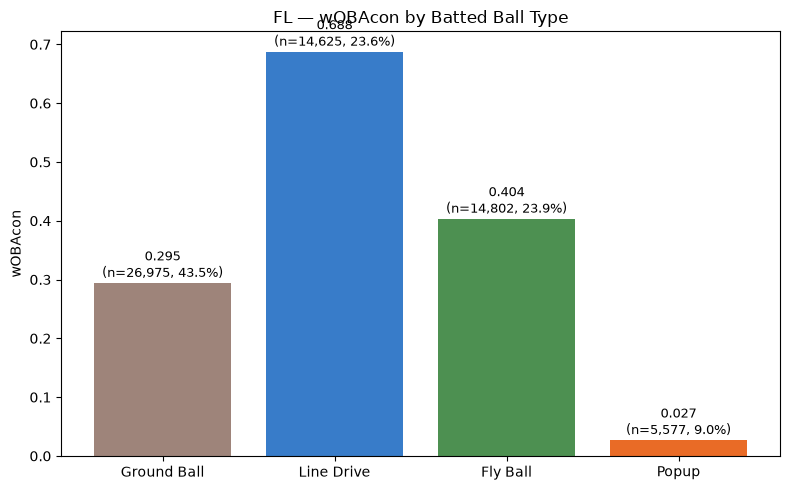

In [ ]:
# ── wOBA by batted ball type (FL) ─────────────────────────────────────────────
# Standard LA-based batted ball classification (consistent with AIR_LA_MIN=10
# used elsewhere in this analysis for the air-ball flag)
def classify_bb_type(angle):
    if angle < 10:
        return "Ground Ball"
    elif angle < 25:
        return "Line Drive"
    elif angle < 50:
        return "Fly Ball"
    else:
        return "Popup"

fl["bb_type"] = fl["angle"].apply(classify_bb_type)

# wOBA weights already validated earlier (standard linear weights, contact-only)
WOBA_W = {"single": 0.88, "double": 1.25, "triple": 1.58,
          "homerun": 2.03, "home_run": 2.03}
fl["pr_norm"]  = fl["play_result"].astype(str).str.lower().str.replace(" ", "")
fl["woba_val"] = fl["pr_norm"].map(WOBA_W).fillna(0.0)

bb_type_summary = (
    fl.groupby("bb_type")
    .agg(
        n_bbe        = ("woba_val", "size"),
        pct_of_bbe   = ("woba_val", "size"),
        wOBAcon      = ("woba_val", "mean"),
        mean_ev      = ("exit_speed", "mean"),
        hard_hit_pct = ("exit_speed", lambda s: (s >= 95).mean()),
    )
)
bb_type_summary["pct_of_bbe"] = bb_type_summary["n_bbe"] / bb_type_summary["n_bbe"].sum()
bb_type_summary = bb_type_summary.reindex(
    ["Ground Ball", "Line Drive", "Fly Ball", "Popup"]
)

print("── FL wOBAcon by batted ball type ──")
print(bb_type_summary.round(3).to_string())

# Visualize
fig, ax = plt.subplots(figsize=(8, 5))
colors = {"Ground Ball": "#8D6E63", "Line Drive": "#1565C0",
          "Fly Ball": "#2E7D32", "Popup": "#E65100"}
bars = ax.bar(bb_type_summary.index, bb_type_summary["wOBAcon"],
              color=[colors[b] for b in bb_type_summary.index], alpha=0.85)
for bar, (n, pct) in zip(bars, zip(bb_type_summary["n_bbe"], bb_type_summary["pct_of_bbe"])):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
           f"{bar.get_height():.3f}\n(n={n:,}, {pct:.1%})",
           ha="center", fontsize=9)
ax.set_ylabel("wOBAcon")
ax.set_title("FL — wOBAcon by Batted Ball Type")
plt.tight_layout(); plt.show()

── FL wOBAcon: batted ball type × spray zone ──
spray_zone   Pull  Cent  Oppo
bb_type                      
Ground Ball 0.267 0.296 0.385
Line Drive  0.785 0.638 0.642
Fly Ball    0.761 0.257 0.352
Popup       0.026 0.019 0.038

── Sample sizes (n BBE) ──
spray_zone    Pull   Cent  Oppo
bb_type                        
Ground Ball  12593  10745  3637
Line Drive    4870   7427  2328
Fly Ball      3712   7901  3189
Popup         1171   2361  2045


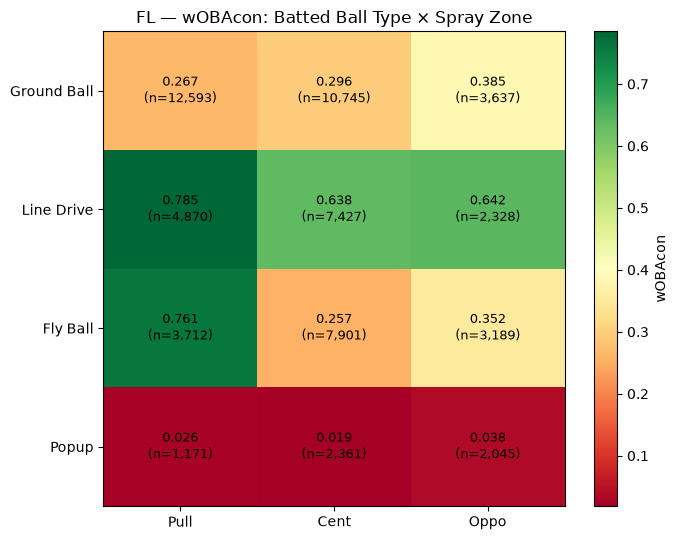

In [ ]:
# ── wOBA by batted ball type × spray zone (FL) ────────────────────────────────
def classify_spray_zone(spray_pull, cutoff=15):
    if spray_pull > cutoff:
        return "Pull"
    elif spray_pull < -cutoff:
        return "Oppo"
    else:
        return "Cent"

fl["spray_zone"] = fl["spray_pull"].apply(classify_spray_zone)

bb_spray_summary = (
    fl.groupby(["bb_type", "spray_zone"])
    .agg(
        n_bbe   = ("woba_val", "size"),
        wOBAcon = ("woba_val", "mean"),
        mean_ev = ("exit_speed", "mean"),
    )
    .reset_index()
)

bb_type_order  = ["Ground Ball", "Line Drive", "Fly Ball", "Popup"]
spray_order    = ["Pull", "Cent", "Oppo"]

woba_pivot = bb_spray_summary.pivot(index="bb_type", columns="spray_zone", values="wOBAcon").reindex(
    bb_type_order)[spray_order]
n_pivot = bb_spray_summary.pivot(index="bb_type", columns="spray_zone", values="n_bbe").reindex(
    bb_type_order)[spray_order]

print("── FL wOBAcon: batted ball type × spray zone ──")
print(woba_pivot.round(3).to_string())
print("\n── Sample sizes (n BBE) ──")
print(n_pivot.to_string())

# Heatmap
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(woba_pivot.to_numpy(dtype=np.float64), cmap="RdYlGn", aspect="auto")
ax.set_xticks(range(len(spray_order)));   ax.set_xticklabels(spray_order)
ax.set_yticks(range(len(bb_type_order))); ax.set_yticklabels(bb_type_order)
for i in range(len(bb_type_order)):
    for j in range(len(spray_order)):
        v = woba_pivot.iloc[i, j]
        n = n_pivot.iloc[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.3f}\n(n={n:,})", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="wOBAcon")
ax.set_title("FL — wOBAcon: Batted Ball Type × Spray Zone")
plt.tight_layout(); plt.show()

Repeat batter-years (2025 → 2026): n = 58
PAA             Pearson +0.799   Spearman +0.823   (p=2.41e-15, n=58)
PAD_raw         Pearson +0.675   Spearman +0.613   (p=3.22e-07, n=58)
PAD_lac         Pearson +0.819   Spearman +0.731   (p=6.97e-11, n=58)
pull_air_pct    Pearson +0.774   Spearman +0.738   (p=3.90e-11, n=58)


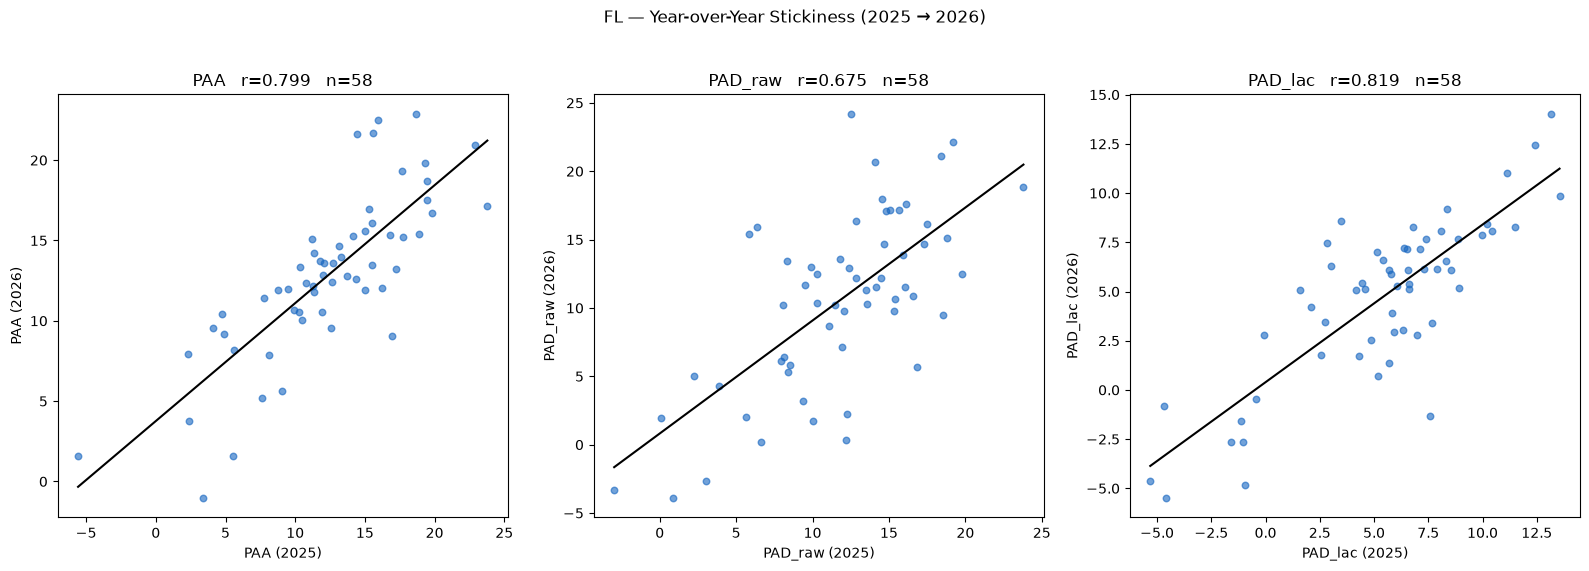

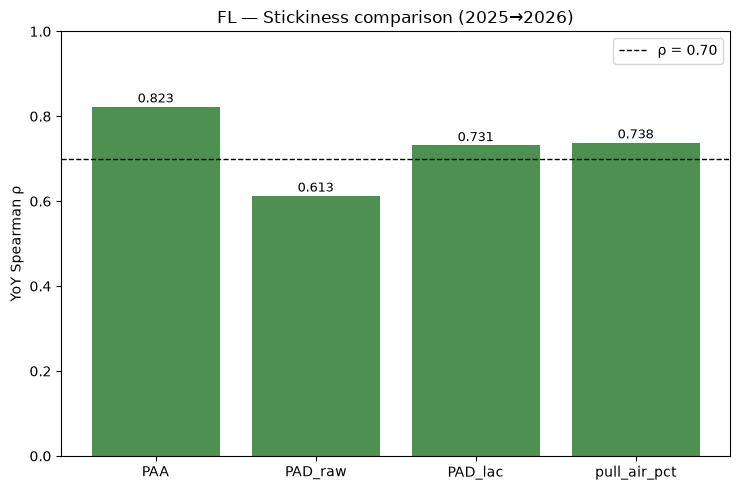

In [ ]:
# ── Year-over-Year Stickiness: PAA, PAD_raw, PAD_lac (2025 → 2026) ──────────

y1, y2 = 2025, 2026

a = qual[qual["year"] == y1][["batter", "PAA", "PAD_raw", "PAD_lac", "pull_air_pct", "n_bbe"]]
b = qual[qual["year"] == y2][["batter", "PAA", "PAD_raw", "PAD_lac", "pull_air_pct", "n_bbe"]]

m = a.merge(b, on="batter", suffixes=(f"_{y1}", f"_{y2}"))
print(f"Repeat batter-years ({y1} → {y2}): n = {len(m)}")

stick_rows = []
for metric in ["PAA", "PAD_raw", "PAD_lac", "pull_air_pct"]:
    pair = m[[f"{metric}_{y1}", f"{metric}_{y2}"]].dropna()
    if len(pair) < 5:
        print(f"{metric}: insufficient paired data (n={len(pair)})")
        continue
    r_p, p_p = stats.pearsonr(pair[f"{metric}_{y1}"], pair[f"{metric}_{y2}"])
    r_s, p_s = spearmanr(pair[f"{metric}_{y1}"], pair[f"{metric}_{y2}"])
    stick_rows.append({"metric": metric, "n": len(pair),
                       "pearson": r_p, "spearman": r_s, "p_value": p_s})
    print(f"{metric:<14}  Pearson {r_p:+.3f}   Spearman {r_s:+.3f}   "
          f"(p={p_s:.2e}, n={len(pair)})")

stick_df = pd.DataFrame(stick_rows)

# ── Plot: scatter for each metric ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, metric in zip(axes, ["PAA", "PAD_raw", "PAD_lac"]):
    pair = m[[f"{metric}_{y1}", f"{metric}_{y2}"]].dropna()
    if len(pair) < 5:
        continue
    ax.scatter(pair[f"{metric}_{y1}"], pair[f"{metric}_{y2}"], s=22, alpha=0.6, color="#1565C0")
    slope, intercept, r, p, se = stats.linregress(pair[f"{metric}_{y1}"], pair[f"{metric}_{y2}"])
    xs = np.linspace(pair[f"{metric}_{y1}"].min(), pair[f"{metric}_{y1}"].max(), 100)
    ax.plot(xs, intercept + slope * xs, color="black", linewidth=1.5)
    ax.set_xlabel(f"{metric} ({y1})")
    ax.set_ylabel(f"{metric} ({y2})")
    ax.set_title(f"{metric}   r={r:.3f}   n={len(pair)}")
plt.suptitle(f"FL — Year-over-Year Stickiness ({y1} → {y2})", y=1.03)
plt.tight_layout(); plt.show()

# ── Bar comparison ────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.bar(stick_df["metric"], stick_df["spearman"], color="#2E7D32", alpha=0.85)
for i, (m_, r) in enumerate(zip(stick_df["metric"], stick_df["spearman"])):
    ax.text(i, r + 0.01, f"{r:.3f}", ha="center", fontsize=9)
ax.axhline(0.70, color="black", linestyle="--", linewidth=1, label="ρ = 0.70")
ax.set_ylabel("YoY Spearman ρ")
ax.set_title(f"FL — Stickiness comparison ({y1}→{y2})")
ax.set_ylim(0, 1.0)
ax.legend()
plt.tight_layout(); plt.show()

In [ ]:
MIN_BBE = 20

Mississippi Mud Monsters: 13 qualified hitter-seasons (≥100 BBE)

FL league average — PAA: 13.5°   PAD_lac: 5.7°

           batter     year   n_bbe    PAA  PAA_vs_avg                       PAA_label  PAD_lac  PAD_lac_vs_avg                       PAD_label
    Knotts, Scout 2025.000 216.000 10.347      -3.185 More Flat (Low LA) than Average   13.030           7.294 More Pull-Oriented than Average
     Furr, Kasten 2026.000 151.000 12.355      -1.176                         Average    8.639           2.902 More Pull-Oriented than Average
     Diaz, Victor 2025.000 172.000 14.137       0.606                         Average    8.517           2.780 More Pull-Oriented than Average
     Holt, Travis 2026.000 177.000 12.115      -1.417                         Average    8.271           2.534 More Pull-Oriented than Average
     Holt, Travis 2025.000 258.000  9.488      -4.044 More Flat (Low LA) than Average    8.105           2.368 More Pull-Oriented than Average
       Rijo, Nilo 2025.000 1

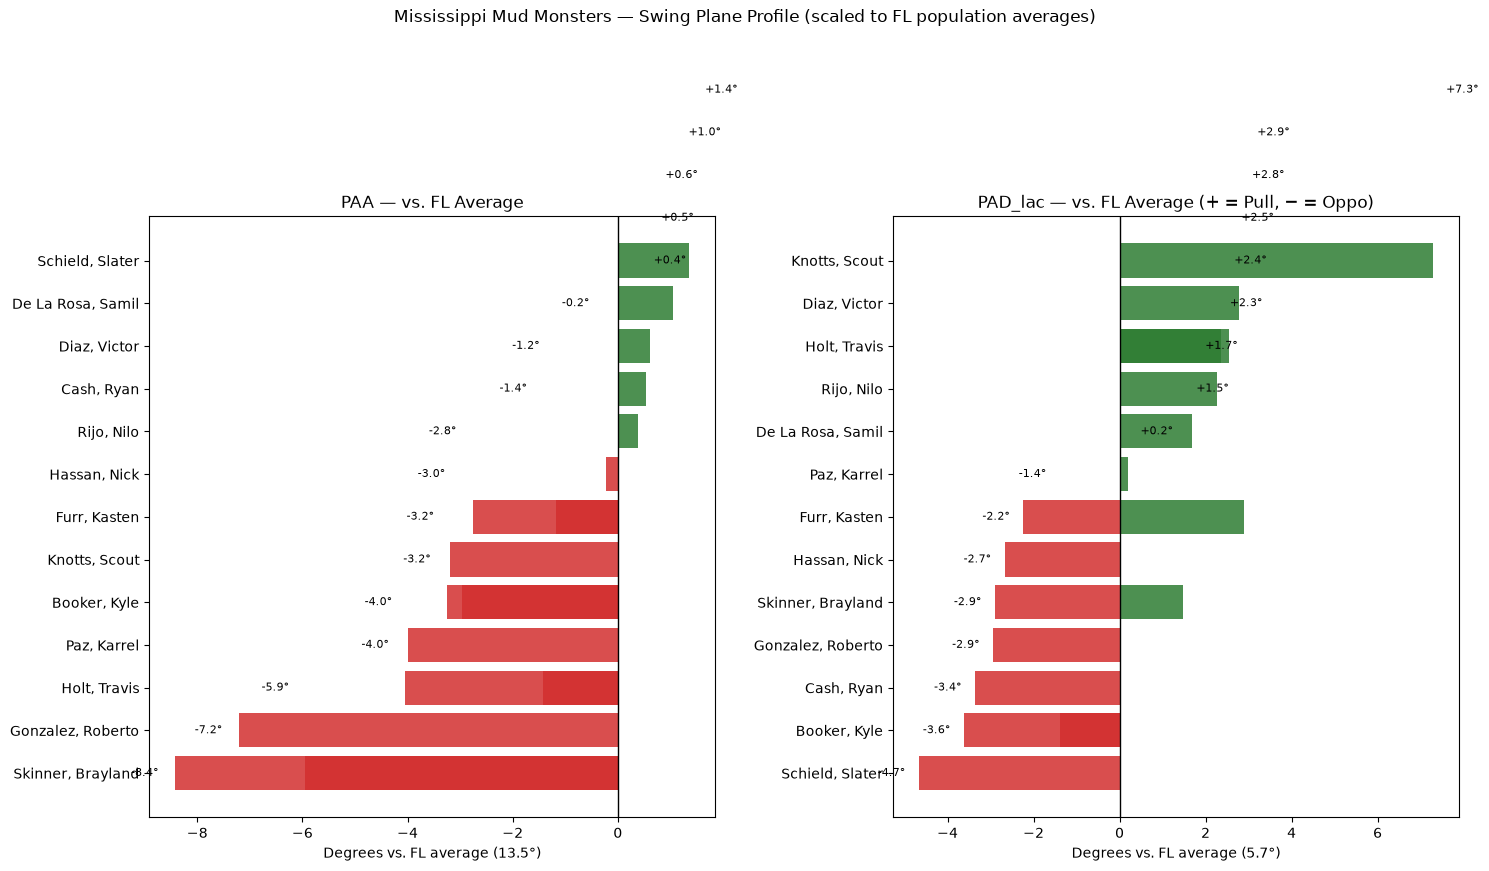

In [46]:
# ── Mississippi Mud Monsters — PAA & PAD_lac, scaled to FL averages ─────────

TEAM_NAME = "Mississippi Mud Monsters"

# ── Get roster batter_ids for the relevant year(s) and filter qual ───────────
roster_sql = text("""
    SELECT DISTINCT batter, batter_team
    FROM pitches
    WHERE batter_team ILIKE :team
""")
with engine.connect() as conn:
    roster = pd.read_sql(roster_sql, conn, params={"team": f"%{TEAM_NAME}%"})

roster_batters = roster["batter"].unique().tolist()
team_qual = qual[qual["batter"].isin(roster_batters)].copy()

print(f"{TEAM_NAME}: {team_qual['batter'].nunique()} qualified hitter-seasons "
      f"(≥{MIN_BBE} BBE)")

# ── Center both metrics on the FL population mean ────────────────────────────
paa_mean, paa_std   = qual["PAA"].mean(),     qual["PAA"].std()
pad_mean, pad_std    = qual["PAD_lac"].mean(), qual["PAD_lac"].std()

team_qual["PAA_vs_avg"]     = team_qual["PAA"]     - paa_mean
team_qual["PAD_lac_vs_avg"] = team_qual["PAD_lac"] - pad_mean

# ── Coach-facing labels (relative to population spread, not absolute degrees) ──
def relative_label(val, std, high_word, low_word, k=0.5):
    if val > k * std:
        return f"More {high_word} than Average"
    elif val < -k * std:
        return f"More {low_word} than Average"
    else:
        return "Average"

team_qual["PAA_label"] = team_qual["PAA_vs_avg"].apply(
    lambda v: relative_label(v, paa_std, "Steep (High LA)", "Flat (Low LA)"))
team_qual["PAD_label"] = team_qual["PAD_lac_vs_avg"].apply(
    lambda v: relative_label(v, pad_std, "Pull-Oriented", "Oppo-Oriented"))

display_cols = ["batter", "year", "n_bbe", "PAA", "PAA_vs_avg", "PAA_label",
                "PAD_lac", "PAD_lac_vs_avg", "PAD_label"]
print(f"\nFL league average — PAA: {paa_mean:.1f}°   PAD_lac: {pad_mean:.1f}°\n")
print(team_qual[display_cols].sort_values("PAD_lac_vs_avg", ascending=False)
      .to_string(index=False))

# ── Diverging bar chart, both metrics ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, max(5, 0.5 * len(team_qual))))

for ax, metric, mean_val, title in zip(
    axes, ["PAA_vs_avg", "PAD_lac_vs_avg"], [paa_mean, pad_mean],
    ["PAA — vs. FL Average", "PAD_lac — vs. FL Average (+ = Pull, − = Oppo)"]
):
    plot_df = team_qual.sort_values(metric)
    colors = ["#D32F2F" if v < 0 else "#2E7D32" for v in plot_df[metric]]
    ax.barh(plot_df["batter"], plot_df[metric], color=colors, alpha=0.85)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_xlabel(f"Degrees vs. FL average ({mean_val:.1f}°)")
    ax.set_title(title)
    for y, (name, v) in enumerate(zip(plot_df["batter"], plot_df[metric])):
        ax.text(v + (0.3 if v >= 0 else -0.3), y, f"{v:+.1f}°",
               va="center", ha="left" if v >= 0 else "right", fontsize=8)

plt.suptitle(f"{TEAM_NAME} — Swing Plane Profile (scaled to FL population averages)", y=1.02)
plt.tight_layout(); plt.show()